<a href="https://colab.research.google.com/github/sabbirpuspo/smart-grid-stability-ml-benchmark/blob/main/smart_grid_stability_ml_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# Project: Smart Grid Stability Prediction
# Purpose: Machine Learning Benchmark
# Dataset: Electrical Grid Stability Simulated Data
# Environment: Google Colab
# ============================================================

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nProject environment initialized successfully.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1

Project environment initialized successfully.


In [ ]:
# ============================================================
# Step 1: Mount Google Drive
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully.")

Mounted at /content/drive
Google Drive connected successfully.


In [ ]:
# ============================================================
# Step 2: Locate the dataset
# ============================================================

import os

dataset_folder = "/content/drive/MyDrive/Smart Grid Stability Dataset"

print("Files in the dataset folder:")

for filename in os.listdir(dataset_folder):
    print(filename)

Files in the dataset folder:
smart_grid_stability_augmented.csv


In [ ]:
# ============================================================
# Step 3: Load the smart-grid dataset
# ============================================================

import pandas as pd

file_path = os.path.join(
    dataset_folder,
    "smart_grid_stability_augmented.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of samples:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of samples: 60000
Number of columns: 14


In [ ]:
df.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [ ]:
print(df.columns.tolist())

['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4', 'stab', 'stabf']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    60000 non-null  float64
 1   tau2    60000 non-null  float64
 2   tau3    60000 non-null  float64
 3   tau4    60000 non-null  float64
 4   p1      60000 non-null  float64
 5   p2      60000 non-null  float64
 6   p3      60000 non-null  float64
 7   p4      60000 non-null  float64
 8   g1      60000 non-null  float64
 9   g2      60000 non-null  float64
 10  g3      60000 non-null  float64
 11  g4      60000 non-null  float64
 12  stab    60000 non-null  float64
 13  stabf   60000 non-null  object 
dtypes: float64(13), object(1)
memory usage: 6.4+ MB


In [ ]:
df["stabf"].value_counts()

,count
stabf,
unstable,38280
stable,21720


In [ ]:
print("Class counts:")
print(df["stabf"].value_counts())

print("\nClass percentages:")
print(
    (df["stabf"].value_counts(normalize=True) * 100).round(2)
)


Class counts:
stabf
unstable    38280
stable      21720
Name: count, dtype: int64

Class percentages:
stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64


In [ ]:
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64


In [ ]:
print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print(
    "Duplicate percentage:",
    round(df.duplicated().mean() * 100, 2),
    "%"
)

Total rows: 60000
Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [ ]:
print(
    pd.crosstab(
        df["stabf"],
        df["stab"] > 0,
        rownames=["Stability label"],
        colnames=["stab > 0"]
    )
)

stab > 0         False  True 
Stability label              
stable           21720      0
unstable             0  38280


stabf
unstable    38280
stable      21720
Name: count, dtype: int64


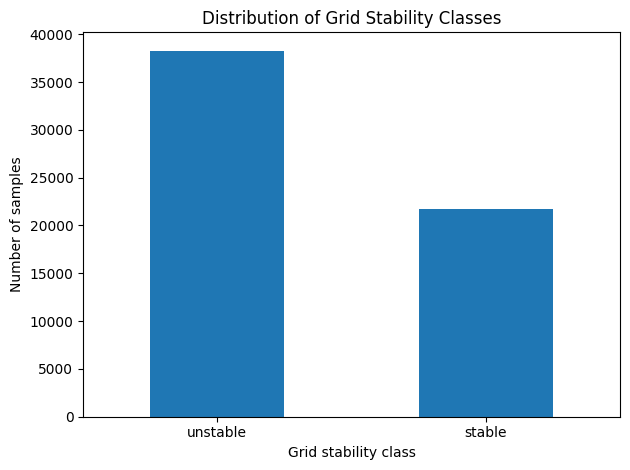

In [ ]:
class_counts = df["stabf"].value_counts()

print(class_counts)

class_counts.plot(
    kind="bar",
    xlabel="Grid stability class",
    ylabel="Number of samples",
    title="Distribution of Grid Stability Classes",
    rot=0
)

plt.tight_layout()
plt.show()


In [ ]:
print("Column data types:")
print(df.dtypes)

print("\nUnique stability labels:")
print(df["stabf"].unique())

Column data types:
tau1     float64
tau2     float64
tau3     float64
tau4     float64
p1       float64
p2       float64
p3       float64
p4       float64
g1       float64
g2       float64
g3       float64
g4       float64
stab     float64
stabf     object
dtype: object

Unique stability labels:
['unstable' 'stable']


In [ ]:
print(df["stab"].describe())

print("\nStability label versus numerical measure:")
print(pd.crosstab(df["stabf"], df["stab"] > 0))


count    60000.000000
mean         0.015731
std          0.036917
min         -0.080760
25%         -0.015557
50%          0.017142
75%          0.044878
max          0.109403
Name: stab, dtype: float64

Stability label versus numerical measure:
stab      False  True 
stabf                 
stable    21720      0
unstable      0  38280


In [ ]:
# Define the 12 input features
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p1", "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

# Create input features and target
X = df[feature_columns]
y = df["stabf"]

# Check their shapes
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

# Preview the input features
print("\nFirst five rows of X:")
print(X.head())

print("\nFirst five target labels:")
print(y.head())

Input features shape: (60000, 12)
Target shape: (60000,)

First five rows of X:
       tau1      tau2      tau3      tau4        p1        p2        p3  \
0  2.959060  3.079885  8.381025  9.780754  3.763085 -0.782604 -1.257395   
1  9.304097  4.902524  3.047541  1.369357  5.067812 -1.940058 -1.872742   
2  8.971707  8.848428  3.046479  1.214518  3.405158 -1.207456 -1.277210   
3  0.716415  7.669600  4.486641  2.340563  3.963791 -1.027473 -1.938944   
4  3.134112  7.608772  4.943759  9.857573  3.525811 -1.125531 -1.845975   

         p4        g1        g2        g3        g4  
0 -1.723086  0.650456  0.859578  0.887445  0.958034  
1 -1.255012  0.413441  0.862414  0.562139  0.781760  
2 -0.920492  0.163041  0.766689  0.839444  0.109853  
3 -0.997374  0.446209  0.976744  0.929381  0.362718  
4 -0.554305  0.797110  0.455450  0.656947  0.820923  

First five target labels:
0    unstable
1      stable
2    unstable
3    unstable
4    unstable
Name: stabf, dtype: object


In [ ]:
# Calculate descriptive statistics for all input features
feature_summary = X.describe().T

# Display each feature's minimum, maximum, mean, and standard deviation
print(
    feature_summary[
        ["min", "max", "mean", "std"]
    ].round(4)
)

         min     max   mean     std
tau1  0.5008  9.9995  5.250  2.7424
tau2  0.5001  9.9998  5.250  2.7424
tau3  0.5001  9.9998  5.250  2.7424
tau4  0.5001  9.9998  5.250  2.7424
p1    1.5826  5.8644  3.750  0.7521
p2   -1.9999 -0.5000 -1.250  0.4330
p3   -1.9999 -0.5000 -1.250  0.4330
p4   -1.9999 -0.5000 -1.250  0.4330
g1    0.0500  0.9999  0.525  0.2742
g2    0.0500  1.0000  0.525  0.2742
g3    0.0500  1.0000  0.525  0.2742
g4    0.0500  1.0000  0.525  0.2742


In [ ]:
# Calculate correlations between the 12 input features
correlation_matrix = X.corr()

# Display the correlation matrix
print(correlation_matrix.round(2))

      tau1  tau2  tau3  tau4    p1    p2    p3    p4    g1    g2    g3    g4
tau1  1.00 -0.00 -0.00 -0.00  0.03 -0.02 -0.02 -0.02  0.01  0.01  0.01  0.01
tau2 -0.00  1.00  0.01  0.01  0.00 -0.00 -0.00 -0.00 -0.01  0.01  0.00  0.00
tau3 -0.00  0.01  1.00  0.01  0.00 -0.00 -0.00 -0.00 -0.01  0.00  0.01  0.00
tau4 -0.00  0.01  0.01  1.00  0.00 -0.00 -0.00 -0.00 -0.01  0.00  0.00  0.01
p1    0.03  0.00  0.00  0.00  1.00 -0.58 -0.58 -0.58  0.00  0.00  0.00  0.00
p2   -0.02 -0.00 -0.00 -0.00 -0.58  1.00  0.00  0.00 -0.00 -0.00  0.00  0.00
p3   -0.02 -0.00 -0.00 -0.00 -0.58  0.00  1.00  0.00 -0.00  0.00 -0.00  0.00
p4   -0.02 -0.00 -0.00 -0.00 -0.58  0.00  0.00  1.00 -0.00  0.00  0.00 -0.00
g1    0.01 -0.01 -0.01 -0.01  0.00 -0.00 -0.00 -0.00  1.00  0.00  0.00  0.00
g2    0.01  0.01  0.00  0.00  0.00 -0.00  0.00  0.00  0.00  1.00 -0.01 -0.01
g3    0.01  0.00  0.01  0.00  0.00  0.00 -0.00  0.00  0.00 -0.01  1.00 -0.01
g4    0.01  0.00  0.00  0.01  0.00  0.00  0.00 -0.00  0.00 -0.01 -0.01  1.00

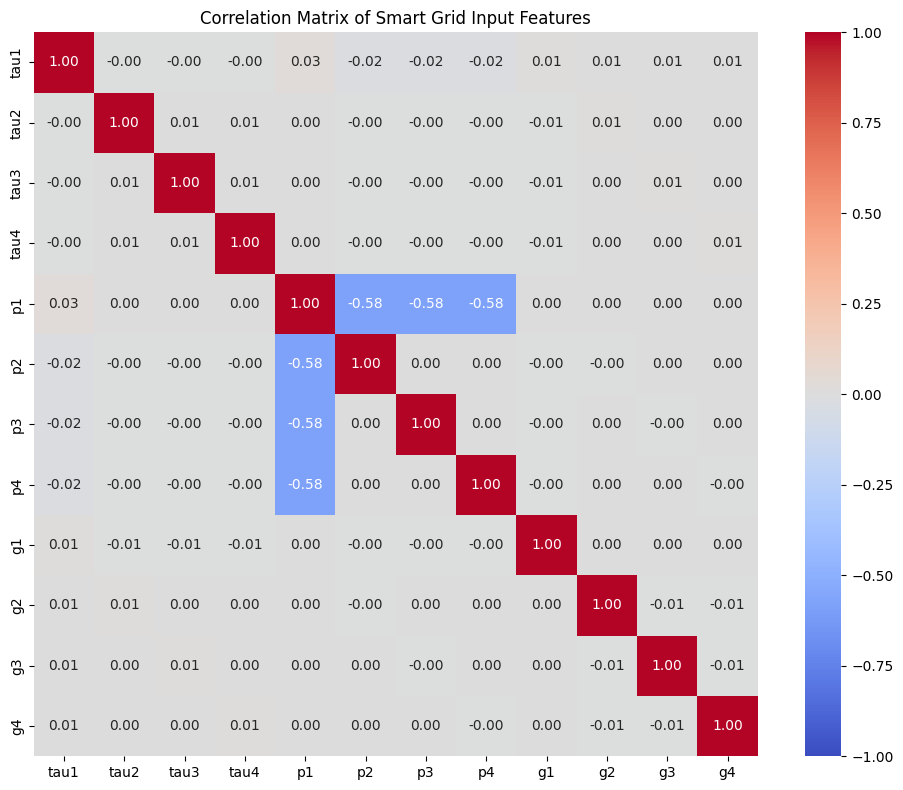

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Matrix of Smart Grid Input Features")
plt.tight_layout()
plt.show()

In [ ]:
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p1", "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

X = df[feature_columns]
y = df["stabf"]

In [ ]:
print("Feature matrix X shape:", X.shape)
print("Target labels y shape:", y.shape)

print("\nTarget class counts:")
print(y.value_counts())

print("\nTarget class proportions (%):")
print((y.value_counts(normalize=True) * 100).round(2))

Feature matrix X shape: (60000, 12)
Target labels y shape: (60000,)

Target class counts:
stabf
unstable    38280
stable      21720
Name: count, dtype: int64

Target class proportions (%):
stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64


In [ ]:
import numpy as np

# Calculate p1 from the three consumer power values
p1_calculated = (
    df["p2"] + df["p3"] + df["p4"]
).abs()

# Measure the difference from the recorded p1
p1_error = (df["p1"] - p1_calculated).abs()

print("Rows in dataset:", len(df))
print(
    "Rows where p1 matches the formula:",
    np.isclose(
        df["p1"],
        p1_calculated,
        atol=1e-8
    ).sum()
)
print("Maximum absolute difference:", p1_error.max())

Rows in dataset: 60000
Rows where p1 matches the formula: 60000
Maximum absolute difference: 6.217248937900877e-15


In [ ]:
# Sort the three consumer nodes into a canonical order.
# Each consumer node is represented by its tau, p, and g values.

def canonical_key(row):
    consumer_nodes = [
        (round(row["tau2"], 8),
         round(row["p2"], 8),
         round(row["g2"], 8)),

        (round(row["tau3"], 8),
         round(row["p3"], 8),
         round(row["g3"], 8)),

        (round(row["tau4"], 8),
         round(row["p4"], 8),
         round(row["g4"], 8))
    ]

    # Sorting makes the key independent of consumer-node order.
    consumer_nodes = tuple(sorted(consumer_nodes))

    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        consumer_nodes,
        round(row["stab"], 8),
        row["stabf"]
    )


# Create a canonical key for every row
canonical_keys = df.apply(canonical_key, axis=1)

# Count how many rows correspond to each canonical configuration
group_sizes = canonical_keys.value_counts()

print("Total rows:", len(df))
print("Unique canonical configurations:", len(group_sizes))
print(
    "Groups containing exactly 6 rows:",
    (group_sizes == 6).sum()
)
print(
    "Groups containing a different number of rows:",
    (group_sizes != 6).sum()
)

print("\nDistribution of group sizes:")
print(group_sizes.value_counts().sort_index())

Total rows: 60000
Unique canonical configurations: 10000
Groups containing exactly 6 rows: 10000
Groups containing a different number of rows: 0

Distribution of group sizes:
count
6    10000
Name: count, dtype: int64


In [ ]:
# Create a canonical key using system inputs only.
# Do not include stab or stabf in this key.

def canonical_input_key(row):
    consumer_nodes = [
        (round(row["tau2"], 8),
         round(row["p2"], 8),
         round(row["g2"], 8)),

        (round(row["tau3"], 8),
         round(row["p3"], 8),
         round(row["g3"], 8)),

        (round(row["tau4"], 8),
         round(row["p4"], 8),
         round(row["g4"], 8))
    ]

    # Ignore the ordering of the three consumer nodes.
    consumer_nodes = tuple(sorted(consumer_nodes))

    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        consumer_nodes
    )


# Assign the same group ID to equivalent configurations.
canonical_input_keys = df.apply(canonical_input_key, axis=1)
group_ids = pd.factorize(canonical_input_keys)[0]

# Examine each group and its target labels.
group_summary = (
    df.assign(group_id=group_ids)
      .groupby("group_id")
      .agg(
          row_count=("stabf", "size"),
          unique_labels=("stabf", "nunique"),
          unique_stability_values=("stab", "nunique")
      )
)

print("Unique input configurations:", len(group_summary))

print("\nDistribution of group sizes:")
print(group_summary["row_count"].value_counts().sort_index())

print(
    "\nGroups with inconsistent target labels:",
    (group_summary["unique_labels"] > 1).sum()
)

print(
    "Groups with inconsistent stability values:",
    (group_summary["unique_stability_values"] > 1).sum()
)

Unique input configurations: 10000

Distribution of group sizes:
row_count
6    10000
Name: count, dtype: int64

Groups with inconsistent target labels: 0
Groups with inconsistent stability values: 0


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Step 1: Select the 11 input features
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

X = df[feature_columns]
y = df["stabf"]

print("Input features:", len(feature_columns))
print("X shape:", X.shape)
print("y shape:", y.shape)

Input features: 11
X shape: (60000, 11)
y shape: (60000,)


In [ ]:
# Create a table containing one entry per unique configuration
group_table = pd.DataFrame({
    "group_id": group_ids,
    "target": y.to_numpy()
}).drop_duplicates(subset="group_id")

print("Unique configurations:", len(group_table))

# Split configurations into 80% training and 20% testing.
# Stratification preserves the class proportions.
train_group_ids, test_group_ids = train_test_split(
    group_table["group_id"].to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=group_table["target"]
)

# Assign all six permutations of each configuration
# to the same split.
train_mask = np.isin(group_ids, train_group_ids)
test_mask = np.isin(group_ids, test_group_ids)

train_idx = np.flatnonzero(train_mask)
test_idx = np.flatnonzero(test_mask)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Check that no configuration appears in both sets
train_groups = np.unique(group_ids[train_idx])
test_groups = np.unique(group_ids[test_idx])

print("\nTraining configurations:", len(train_groups))
print("Testing configurations:", len(test_groups))
print(
    "Configurations shared between sets:",
    len(np.intersect1d(train_groups, test_groups))
)

Unique configurations: 10000

Training features: (48000, 11)
Testing features: (12000, 11)

Training target distribution:
stabf
unstable    30624
stable      17376
Name: count, dtype: int64

Testing target distribution:
stabf
unstable    7656
stable      4344
Name: count, dtype: int64

Training configurations: 8000
Testing configurations: 2000
Configurations shared between sets: 0


In [ ]:
# Step 1: Import the required tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Step 2: Build the model pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Step 3: Train the model using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict the labels for the unseen test data
y_pred = logistic_model.predict(X_test)

# Calculate the probability of the "unstable" class
unstable_index = list(logistic_model.classes_).index("unstable")
y_prob = logistic_model.predict_proba(X_test)[:, unstable_index]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(
    (y_test == "unstable").astype(int),
    y_prob
)

print("=== Logistic Regression: Test Results ===")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")
print(f"ROC-AUC:           {roc_auc:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["stable", "unstable"]
))

=== Logistic Regression: Test Results ===
Accuracy:          0.8200
Balanced accuracy: 0.7941
ROC-AUC:           0.8919

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.7800    0.7003    0.7380      4344
    unstable     0.8393    0.8879    0.8629      7656

    accuracy                         0.8200     12000
   macro avg     0.8096    0.7941    0.8005     12000
weighted avg     0.8178    0.8200    0.8177     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3042 1302]
 [ 858 6798]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train using the same training data
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict classes and probabilities
rf_pred = rf_model.predict(X_test)

unstable_index = list(rf_model.classes_).index("unstable")
rf_prob = rf_model.predict_proba(X_test)[:, unstable_index]

# Calculate metrics
print("=== Random Forest: Test Results ===")
print(f"Accuracy:          {accuracy_score(y_test, rf_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test, rf_pred):.4f}"
)
print(
    f"ROC-AUC:           "
    f"{roc_auc_score((y_test == 'unstable').astype(int), rf_prob):.4f}"
)

print("\n=== Classification Report ===")
print(classification_report(y_test, rf_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(confusion_matrix(
    y_test,
    rf_pred,
    labels=["stable", "unstable"]
))

=== Random Forest: Test Results ===
Accuracy:          0.9357
Balanced accuracy: 0.9268
ROC-AUC:           0.9879

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.9257    0.8943    0.9097      4344
    unstable     0.9412    0.9592    0.9501      7656

    accuracy                         0.9357     12000
   macro avg     0.9334    0.9268    0.9299     12000
weighted avg     0.9356    0.9357    0.9355     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3885  459]
 [ 312 7344]]


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train using the existing training set
gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Generate predictions on the existing test set
gb_pred = gb_model.predict(X_test)

# Extract the probability for the unstable class
unstable_index = list(gb_model.classes_).index("unstable")
gb_prob = gb_model.predict_proba(X_test)[:, unstable_index]

print("=== Gradient Boosting: Test Results ===")
print(f"Accuracy:          {accuracy_score(y_test, gb_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test, gb_pred):.4f}"
)
print(
    f"ROC-AUC:           "
    f"{roc_auc_score((y_test == 'unstable').astype(int), gb_prob):.4f}"
)

print("\n=== Classification Report ===")
print(classification_report(y_test, gb_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(
    confusion_matrix(
        y_test,
        gb_pred,
        labels=["stable", "unstable"]
    )
)

=== Gradient Boosting: Test Results ===
Accuracy:          0.9290
Balanced accuracy: 0.9131
ROC-AUC:           0.9818

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.9431    0.8554    0.8972      4344
    unstable     0.9221    0.9707    0.9458      7656

    accuracy                         0.9290     12000
   macro avg     0.9326    0.9131    0.9215     12000
weighted avg     0.9297    0.9290    0.9282     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3716  628]
 [ 224 7432]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Store predictions and probabilities from our three models
model_results = {
    "Logistic Regression": (y_pred, y_prob),
    "Random Forest": (rf_pred, rf_prob),
    "Gradient Boosting": (gb_pred, gb_prob)
}

rows = []

for model_name, (predictions, probabilities) in model_results.items():

    # Confusion matrix order: stable, unstable
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["stable", "unstable"]
    )

    rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "unstable").astype(int),
            probabilities
        ),
        "Stable recall": recall_score(
            y_test, predictions, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_test, predictions, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

comparison_df = pd.DataFrame(rows)

# Sort by balanced accuracy for this preliminary comparison
comparison_df = comparison_df.sort_values(
    by="Balanced accuracy",
    ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Balanced accuracy  ROC-AUC  Stable recall  Unstable recall  Unstable cases missed  False alarms
      Random Forest    0.9358             0.9268   0.9879         0.8943           0.9592                    312           459
  Gradient Boosting    0.9290             0.9131   0.9818         0.8554           0.9707                    224           628
Logistic Regression    0.8200             0.7941   0.8919         0.7003           0.8879                    858          1302


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract Random Forest feature importance scores
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("=== Random Forest Feature Importance ===")
print(importance_df.to_string(
    index=False,
    formatters={"Importance": "{:.4f}".format}
))

=== Random Forest Feature Importance ===
Feature Importance
   tau1     0.1306
   tau2     0.1267
   tau4     0.1261
   tau3     0.1255
     g1     0.1066
     g3     0.1049
     g4     0.1048
     g2     0.1033
     p4     0.0238
     p3     0.0238
     p2     0.0238


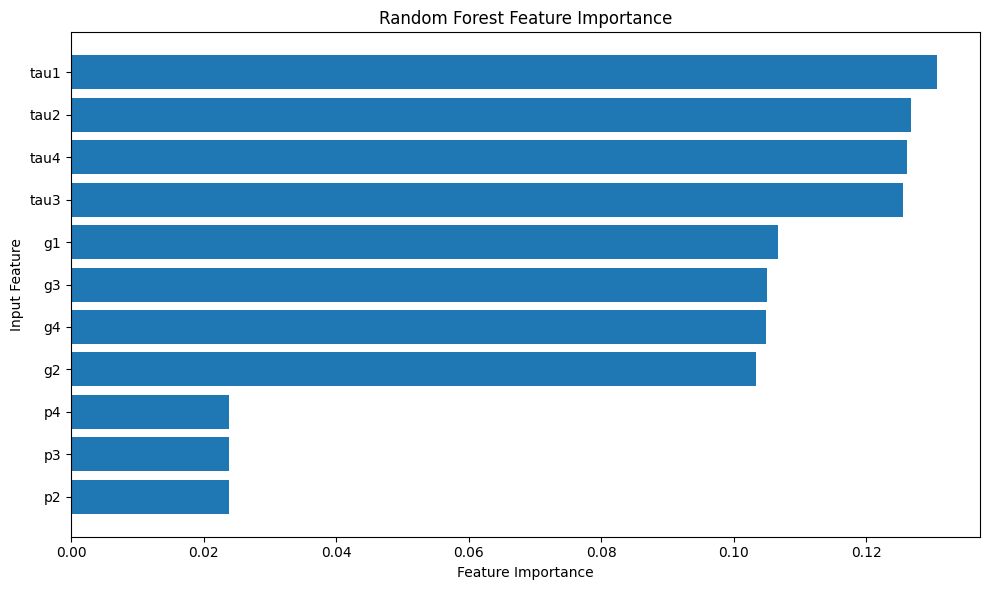

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Input Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import balanced_accuracy_score

# Baseline performance on the held-out test set
baseline_predictions = rf_model.predict(X_test)

baseline_score = balanced_accuracy_score(
    y_test,
    baseline_predictions
)

# Group related input features
feature_groups = {
    "Time constants (tau)": [
        "tau1", "tau2", "tau3", "tau4"
    ],
    "Conductance parameters (g)": [
        "g1", "g2", "g3", "g4"
    ],
    "Power parameters (p)": [
        "p2", "p3", "p4"
    ]
}

rng = np.random.default_rng(42)
n_repeats = 10
group_results = []

for group_name, columns in feature_groups.items():

    score_drops = []

    for repeat in range(n_repeats):

        # Create a copy of the original test features
        X_permuted = X_test.copy()

        # Shuffle the selected feature family together
        shuffled_indices = rng.permutation(len(X_test))

        X_permuted.loc[:, columns] = (
            X_test.iloc[shuffled_indices][columns].to_numpy()
        )

        # Evaluate after disrupting the relationship
        # between this feature family and the target
        permuted_predictions = rf_model.predict(X_permuted)

        permuted_score = balanced_accuracy_score(
            y_test,
            permuted_predictions
        )

        score_drops.append(
            baseline_score - permuted_score
        )

    group_results.append({
        "Feature family": group_name,
        "Mean balanced-accuracy drop": np.mean(score_drops),
        "Standard deviation": np.std(score_drops, ddof=1)
    })

group_importance_df = pd.DataFrame(group_results)

print(f"Baseline balanced accuracy: {baseline_score:.4f}")
print("\n=== Grouped Permutation Importance ===")
print(group_importance_df.round(4).to_string(index=False))

Baseline balanced accuracy: 0.9268

=== Grouped Permutation Importance ===
            Feature family  Mean balanced-accuracy drop  Standard deviation
      Time constants (tau)                       0.3352              0.0043
Conductance parameters (g)                       0.2440              0.0032
      Power parameters (p)                      -0.0010              0.0008


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Keep only the tau and g feature families
tau_g_features = [
    "tau1", "tau2", "tau3", "tau4",
    "g1", "g2", "g3", "g4"
]

# Train a new Random Forest with the same settings
rf_tau_g_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_tau_g_model.fit(
    X_train[tau_g_features],
    y_train
)

print("Reduced Random Forest training completed!")
print("Number of input features:", len(tau_g_features))

Reduced Random Forest training completed!
Number of input features: 8


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Get predictions and probabilities for the 11-feature model
rf_full_pred = rf_model.predict(X_test)

rf_full_prob = rf_model.predict_proba(X_test)[
    :, list(rf_model.classes_).index("unstable")
]

# Get predictions and probabilities for the 8-feature model
rf_reduced_pred = rf_tau_g_model.predict(
    X_test[tau_g_features]
)

rf_reduced_prob = rf_tau_g_model.predict_proba(
    X_test[tau_g_features]
)[:, list(rf_tau_g_model.classes_).index("unstable")]

# Verify probability array lengths
print("Test labels:", len(y_test))
print("Full-model probabilities:", len(rf_full_prob))
print("Reduced-model probabilities:", len(rf_reduced_prob))

# Compare both models
models = {
    "Random Forest: 11 features": (rf_full_pred, rf_full_prob),
    "Random Forest: 8 features": (rf_reduced_pred, rf_reduced_prob)
}

comparison = []

for name, (pred, prob) in models.items():
    cm = confusion_matrix(
        y_test,
        pred,
        labels=["stable", "unstable"]
    )

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(
            (y_test == "unstable").astype(int),
            prob
        ),
        "Stable recall": recall_score(
            y_test, pred, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_test, pred, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

ablation_results = pd.DataFrame(comparison)

print("\n=== Feature Ablation Results ===")
print(ablation_results.round(4).to_string(index=False))

Test labels: 12000
Full-model probabilities: 12000
Reduced-model probabilities: 12000

=== Feature Ablation Results ===
                     Model  Accuracy  Balanced accuracy  ROC-AUC  Stable recall  Unstable recall  Unstable cases missed  False alarms
Random Forest: 11 features    0.9358             0.9268   0.9879         0.8943           0.9592                    312           459
 Random Forest: 8 features    0.9409             0.9319   0.9895         0.8994           0.9645                    272           437


In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    make_scorer
)

# Recover the configuration groups corresponding to training rows
groups_train = np.asarray(group_ids)[train_idx]

print("Training rows:", len(X_train))
print("Unique training configurations:", len(np.unique(groups_train)))

# Five folds, stratified by class and separated by configuration group
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate both feature sets using the same folds
feature_sets = {
    "Random Forest: 11 features": list(X_train.columns),
    "Random Forest: 8 features": tau_g_features
}

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": make_scorer(balanced_accuracy_score),
    "roc_auc": "roc_auc",
    "stable_recall": make_scorer(
        recall_score, pos_label="stable"
    ),
    "unstable_recall": make_scorer(
        recall_score, pos_label="unstable"
    )
}

cv_rows = []

for model_name, features in feature_sets.items():

    print(f"\nEvaluating {model_name}...")

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_validate(
        model,
        X_train[features],
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    row = {"Model": model_name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} mean"] = values.mean()
        row[f"{metric} std"] = values.std(ddof=1)

    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)

print("\n=== Five-Fold Group Cross-Validation Results ===")
print(cv_results.round(4).to_string(index=False))

Training rows: 48000
Unique training configurations: 8000

Evaluating Random Forest: 11 features...

Evaluating Random Forest: 8 features...

=== Five-Fold Group Cross-Validation Results ===
                     Model  accuracy mean  accuracy std  balanced_accuracy mean  balanced_accuracy std  roc_auc mean  roc_auc std  stable_recall mean  stable_recall std  unstable_recall mean  unstable_recall std
Random Forest: 11 features         0.9334        0.0070                  0.9245                 0.0081        0.9855       0.0027              0.8919             0.0152                0.9570               0.0076
 Random Forest: 8 features         0.9367        0.0081                  0.9280                 0.0096        0.9872       0.0023              0.8963             0.0174                0.9596               0.0069


In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score
)

# Reuse the same five group-aware folds
fold_splits = list(
    cv.split(X_train, y_train, groups=groups_train)
)

feature_sets = {
    "11 features": list(X_train.columns),
    "8 features": tau_g_features
}

fold_results = []

for fold_number, (fit_idx, val_idx) in enumerate(
    fold_splits, start=1
):
    X_fit = X_train.iloc[fit_idx]
    X_val = X_train.iloc[val_idx]

    y_fit = y_train.iloc[fit_idx]
    y_val = y_train.iloc[val_idx]

    for model_name, features in feature_sets.items():

        model = RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fit[features], y_fit)

        predictions = model.predict(X_val[features])

        unstable_index = list(model.classes_).index("unstable")
        probabilities = model.predict_proba(
            X_val[features]
        )[:, unstable_index]

        fold_results.append({
            "Fold": fold_number,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Balanced accuracy": balanced_accuracy_score(
                y_val, predictions
            ),
            "ROC-AUC": roc_auc_score(
                (y_val == "unstable").astype(int),
                probabilities
            )
        })

fold_results_df = pd.DataFrame(fold_results)

print("=== Performance by Validation Fold ===")
print(fold_results_df.round(4).to_string(index=False))

=== Performance by Validation Fold ===
 Fold       Model  Accuracy  Balanced accuracy  ROC-AUC
    1 11 features    0.9347             0.9248   0.9860
    1  8 features    0.9355             0.9265   0.9876
    2 11 features    0.9299             0.9189   0.9848
    2  8 features    0.9323             0.9217   0.9863
    3 11 features    0.9375             0.9268   0.9865
    3  8 features    0.9382             0.9270   0.9883
    4 11 features    0.9416             0.9364   0.9886
    4  8 features    0.9494             0.9443   0.9900
    5 11 features    0.9234             0.9155   0.9814
    5  8 features    0.9279             0.9204   0.9837


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)
import pandas as pd

# Use 3 group-aware folds for a faster initial search
cv_fast = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Smaller search space
param_distributions_fast = {
    "n_estimators": [100, 150, 200],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 0.8]
}

# Keep the model focused on our selected 8 features
rf_base_fast = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_search_fast = RandomizedSearchCV(
    estimator=rf_base_fast,
    param_distributions=param_distributions_fast,
    n_iter=6,
    scoring="balanced_accuracy",
    refit=True,
    cv=cv_fast,
    random_state=42,
    n_jobs=1,
    verbose=2,
    return_train_score=False
)

print("Starting the faster hyperparameter search...")

rf_search_fast.fit(
    X_train[tau_g_features],
    y_train,
    groups=groups_train
)

print("\nSearch completed!")
print("\nBest parameters:")
print(rf_search_fast.best_params_)

print(
    "\nBest mean cross-validation balanced accuracy:",
    round(rf_search_fast.best_score_, 4)
)

# Show the tested configurations
search_results_fast = pd.DataFrame(
    rf_search_fast.cv_results_
)

print("\n=== Tested Configurations ===")
print(
    search_results_fast[
        [
            "mean_test_score",
            "std_test_score",
            "params"
        ]
    ]
    .sort_values("mean_test_score", ascending=False)
    .round(4)
    .to_string(index=False)
)

Starting the faster hyperparameter search...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   9.2s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   7.2s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   9.0s
[CV] END max_depth=20, max_features=0.8, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time=  30.6s
[CV] END max_depth=20, max_features=0.8, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time=  30.7s
[CV] END max_depth=20, max_features=0.8, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time=  31.4s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=  16.2s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
import pandas as pd

# Baseline model: our original 300-tree Random Forest
baseline_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Tuned model: best parameters from the search
tuned_model = RandomForestClassifier(
    **rf_search_fast.best_params_,
    random_state=42,
    n_jobs=-1
)

# Evaluate both models using identical folds
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

comparison_rows = []

for model_name, model in [
    ("Baseline: 8 features", baseline_model),
    ("Tuned: 8 features", tuned_model)
]:
    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        model,
        X_train[tau_g_features],
        y_train,
        groups=groups_train,
        cv=cv_fast,
        scoring=scoring,
        n_jobs=1
    )

    comparison_rows.append({
        "Model": model_name,
        "Accuracy mean": scores["test_accuracy"].mean(),
        "Balanced accuracy mean":
            scores["test_balanced_accuracy"].mean(),
        "Balanced accuracy std":
            scores["test_balanced_accuracy"].std(ddof=1),
        "ROC-AUC mean": scores["test_roc_auc"].mean()
    })

fair_comparison = pd.DataFrame(comparison_rows)

print("\n=== Fair 3-Fold Comparison ===")
print(fair_comparison.round(4).to_string(index=False))

Evaluating Baseline: 8 features...
Evaluating Tuned: 8 features...

=== Fair 3-Fold Comparison ===
               Model  Accuracy mean  Balanced accuracy mean  Balanced accuracy std  ROC-AUC mean
Baseline: 8 features         0.9336                  0.9248                 0.0026        0.9857
   Tuned: 8 features         0.9332                  0.9239                 0.0016        0.9847


In [ ]:
import pandas as pd

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score

# Compare all models using the same 8 features
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Evaluate both classes, not only the majority class
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "stable_recall": make_scorer(
        recall_score, pos_label="stable"
    ),
    "unstable_recall": make_scorer(
        recall_score, pos_label="unstable"
    )
}

results = []

for model_name, model in models.items():
    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        model,
        X_train[tau_g_features],
        y_train,
        groups=groups_train,
        cv=cv,                  # Same 5 group-aware folds
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    row = {"Model": model_name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} mean"] = values.mean()
        row[f"{metric} std"] = values.std(ddof=1)

    results.append(row)

model_comparison = pd.DataFrame(results)

print("\n=== Five-Fold Group-Aware Model Comparison ===")
print(model_comparison.round(4).to_string(index=False))

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...

=== Five-Fold Group-Aware Model Comparison ===
              Model  accuracy mean  accuracy std  balanced_accuracy mean  balanced_accuracy std  roc_auc mean  roc_auc std  stable_recall mean  stable_recall std  unstable_recall mean  unstable_recall std
Logistic Regression         0.8121        0.0159                  0.7874                 0.0166        0.8902       0.0102              0.6979             0.0241                0.8770               0.0187
      Random Forest         0.9367        0.0081                  0.9280                 0.0096        0.9872       0.0023              0.8963             0.0174                0.9596               0.0069
  Gradient Boosting         0.9128        0.0063                  0.8925                 0.0080        0.9752       0.0035              0.8190             0.0186                0.9660               0.0063


In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Use our selected 8-feature model
rf_cv_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Each training observation receives a prediction from a model
# that did not train on that observation's configuration group.
oof_probabilities = cross_val_predict(
    rf_cv_model,
    X_train[tau_g_features],
    y_train,
    groups=groups_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

# Find the probability column corresponding to "unstable"
classes = np.unique(y_train)
unstable_index = np.where(classes == "unstable")[0][0]

oof_unstable_prob = oof_probabilities[:, unstable_index]

print("Training observations:", len(y_train))
print("Out-of-fold predictions:", len(oof_unstable_prob))
print("Unique configuration groups:", len(np.unique(groups_train)))
print("Cross-validated probabilities generated successfully!")

Training observations: 48000
Out-of-fold predictions: 48000
Unique configuration groups: 8000
Cross-validated probabilities generated successfully!


In [ ]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

threshold_results = []

for threshold in thresholds:

    # Predict unstable whenever its probability meets the threshold
    predictions = np.where(
        oof_unstable_prob >= threshold,
        "unstable",
        "stable"
    )

    cm = confusion_matrix(
        y_train,
        predictions,
        labels=["stable", "unstable"]
    )

    threshold_results.append({
        "Threshold": threshold,
        "Balanced accuracy": balanced_accuracy_score(
            y_train, predictions
        ),
        "Stable recall": recall_score(
            y_train, predictions, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_train, predictions, pos_label="unstable"
        ),
        "Unstable precision": precision_score(
            y_train, predictions, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

threshold_df = pd.DataFrame(threshold_results)

print("=== Threshold Analysis: Training OOF Predictions ===")
print(threshold_df.round(4).to_string(index=False))

=== Threshold Analysis: Training OOF Predictions ===
 Threshold  Balanced accuracy  Stable recall  Unstable recall  Unstable precision  Unstable cases missed  False alarms
      0.30             0.8540         0.7126           0.9954              0.8592                    141          4994
      0.35             0.8801         0.7695           0.9907              0.8834                    284          4006
      0.40             0.8996         0.8161           0.9830              0.9041                    520          3195
      0.45             0.9148         0.8562           0.9734              0.9227                    816          2498
      0.50             0.9270         0.8933           0.9608              0.9407                   1201          1854
      0.55             0.9357         0.9275           0.9440              0.9582                   1716          1260
      0.60             0.9379         0.9517           0.9241              0.9712                   2324          

In [ ]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix
)

# Obtain probabilities from the existing 8-feature model
test_probabilities = rf_tau_g_model.predict_proba(
    X_test[tau_g_features]
)

unstable_index = list(
    rf_tau_g_model.classes_
).index("unstable")

test_unstable_prob = test_probabilities[:, unstable_index]

threshold_test_results = []

for threshold in [0.50, 0.60]:

    # Apply the selected threshold
    predictions = [
        "unstable" if prob >= threshold else "stable"
        for prob in test_unstable_prob
    ]

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["stable", "unstable"]
    )

    threshold_test_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Stable recall": recall_score(
            y_test, predictions, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_test, predictions, pos_label="unstable"
        ),
        "Unstable precision": precision_score(
            y_test, predictions, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

test_threshold_df = pd.DataFrame(threshold_test_results)

print("=== Test-Set Threshold Comparison ===")
print(test_threshold_df.round(4).to_string(index=False))

=== Test-Set Threshold Comparison ===
 Threshold  Accuracy  Balanced accuracy  Stable recall  Unstable recall  Unstable precision  Unstable cases missed  False alarms
       0.5    0.9406             0.9312         0.8973           0.9651              0.9431                    267           446
       0.6    0.9362             0.9408         0.9576           0.9240              0.9746                    582           184


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score
)

# Test thresholds from 0.30 to 0.70 in increments of 0.01
fine_thresholds = np.round(
    np.arange(0.30, 0.701, 0.01), 2
)

fine_results = []

for threshold in fine_thresholds:

    predictions = np.where(
        oof_unstable_prob >= threshold,
        "unstable",
        "stable"
    )

    stable_recall = recall_score(
        y_train,
        predictions,
        pos_label="stable"
    )

    unstable_recall = recall_score(
        y_train,
        predictions,
        pos_label="unstable"
    )

    balanced_acc = balanced_accuracy_score(
        y_train,
        predictions
    )

    fine_results.append({
        "Threshold": threshold,
        "Balanced accuracy": balanced_acc,
        "Stable recall": stable_recall,
        "Unstable recall": unstable_recall
    })

fine_threshold_df = pd.DataFrame(fine_results)

# Identify the threshold with the highest balanced accuracy
best_row = fine_threshold_df.loc[
    fine_threshold_df["Balanced accuracy"].idxmax()
]

print("=== Best Threshold from Training OOF Predictions ===")
print(best_row.round(4).to_string())

print("\n=== Top 10 Thresholds ===")
print(
    fine_threshold_df.sort_values(
        "Balanced accuracy",
        ascending=False
    ).head(10).round(4).to_string(index=False)
)

=== Best Threshold from Training OOF Predictions ===
Threshold            0.6000
Balanced accuracy    0.9379
Stable recall        0.9517
Unstable recall      0.9241

=== Top 10 Thresholds ===
 Threshold  Balanced accuracy  Stable recall  Unstable recall
      0.60             0.9379         0.9517           0.9241
      0.59             0.9377         0.9472           0.9283
      0.58             0.9375         0.9423           0.9327
      0.61             0.9374         0.9555           0.9193
      0.62             0.9373         0.9603           0.9144
      0.57             0.9367         0.9367           0.9367
      0.56             0.9365         0.9326           0.9405
      0.63             0.9362         0.9635           0.9090
      0.55             0.9357         0.9275           0.9440
      0.64             0.9356         0.9672           0.9040


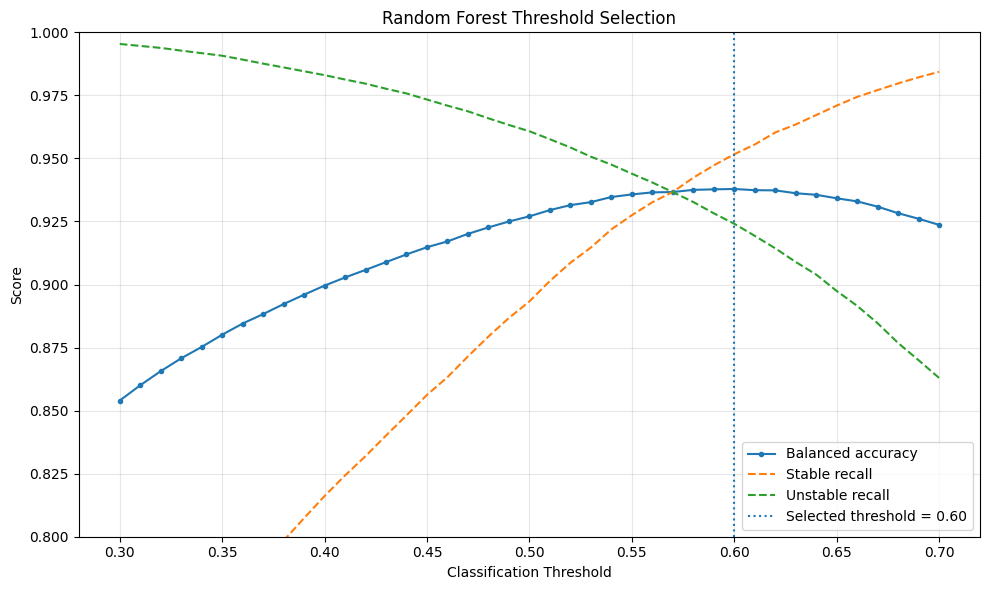

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    fine_threshold_df["Threshold"],
    fine_threshold_df["Balanced accuracy"],
    marker="o",
    markersize=3,
    label="Balanced accuracy"
)

plt.plot(
    fine_threshold_df["Threshold"],
    fine_threshold_df["Stable recall"],
    linestyle="--",
    label="Stable recall"
)

plt.plot(
    fine_threshold_df["Threshold"],
    fine_threshold_df["Unstable recall"],
    linestyle="--",
    label="Unstable recall"
)

plt.axvline(
    x=0.60,
    linestyle=":",
    label="Selected threshold = 0.60"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest Threshold Selection")
plt.ylim(0.80, 1.00)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

# Candidate thresholds
threshold_grid = np.round(
    np.arange(0.30, 0.701, 0.01), 2
)

# Outer folds: evaluate on groups not used for threshold selection
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

nested_results = []

for fold, (outer_train_idx, outer_val_idx) in enumerate(
    outer_cv.split(
        X_train[tau_g_features],
        y_train,
        groups=groups_train
    ),
    start=1
):
    print(f"\nProcessing outer fold {fold}/5...")

    # Separate the outer training and validation data
    X_outer_train = X_train[tau_g_features].iloc[outer_train_idx]
    y_outer_train = y_train.iloc[outer_train_idx]

    X_outer_val = X_train[tau_g_features].iloc[outer_val_idx]
    y_outer_val = y_train.iloc[outer_val_idx]

    groups_outer_train = groups_train[outer_train_idx]
    groups_outer_val = groups_train[outer_val_idx]

    # Confirm that configuration groups do not overlap
    assert len(np.intersect1d(
        groups_outer_train,
        groups_outer_val
    )) == 0, "Group leakage detected!"

    # Inner grouped cross-validation produces out-of-fold
    # probabilities for selecting a threshold
    inner_cv = StratifiedGroupKFold(
        n_splits=3,
        shuffle=True,
        random_state=100 + fold
    )

    inner_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    inner_probabilities = cross_val_predict(
        inner_model,
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
        cv=inner_cv,
        method="predict_proba",
        n_jobs=1
    )

    inner_classes = np.unique(y_outer_train.to_numpy())
    unstable_idx = np.flatnonzero(
        inner_classes == "unstable"
    )[0]

    inner_unstable_prob = inner_probabilities[:, unstable_idx]

    # Select the threshold with the highest inner balanced accuracy
    threshold_scores = []

    for threshold in threshold_grid:
        inner_predictions = np.where(
            inner_unstable_prob >= threshold,
            "unstable",
            "stable"
        )

        threshold_scores.append(
            balanced_accuracy_score(
                y_outer_train,
                inner_predictions
            )
        )

    best_threshold = threshold_grid[
        np.argmax(threshold_scores)
    ]

    # Fit the model on the entire outer training fold
    outer_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    outer_model.fit(X_outer_train, y_outer_train)

    # Evaluate on the outer validation fold
    outer_probabilities = outer_model.predict_proba(X_outer_val)

    outer_unstable_idx = list(
        outer_model.classes_
    ).index("unstable")

    outer_unstable_prob = outer_probabilities[
        :, outer_unstable_idx
    ]

    outer_predictions = np.where(
        outer_unstable_prob >= best_threshold,
        "unstable",
        "stable"
    )

    cm = confusion_matrix(
        y_outer_val,
        outer_predictions,
        labels=["stable", "unstable"]
    )

    nested_results.append({
        "Fold": fold,
        "Selected threshold": best_threshold,
        "Accuracy": accuracy_score(
            y_outer_val, outer_predictions
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_outer_val, outer_predictions
        ),
        "ROC-AUC": roc_auc_score(
            (y_outer_val == "unstable").astype(int),
            outer_unstable_prob
        ),
        "Stable recall": recall_score(
            y_outer_val,
            outer_predictions,
            pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_outer_val,
            outer_predictions,
            pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

    print(f"Selected inner threshold: {best_threshold:.2f}")
    print(
        "Outer balanced accuracy:",
        f"{nested_results[-1]['Balanced accuracy']:.4f}"
    )

# Show the results for each outer fold
nested_df = pd.DataFrame(nested_results)

print("\n=== Nested Group-Aware CV: Individual Folds ===")
print(nested_df.round(4).to_string(index=False))

# Summarize performance and fold-to-fold variation
metrics = [
    "Accuracy",
    "Balanced accuracy",
    "ROC-AUC",
    "Stable recall",
    "Unstable recall"
]

summary = pd.DataFrame({
    "Mean": nested_df[metrics].mean(),
    "Std across folds": nested_df[metrics].std(ddof=1)
})

print("\n=== Nested CV Performance Summary ===")
print(summary.round(4).to_string())

print(
    "\nMean selected threshold:",
    round(nested_df["Selected threshold"].mean(), 3)
)
print(
    "Median selected threshold:",
    round(nested_df["Selected threshold"].median(), 3)
)


Processing outer fold 1/5...
Selected inner threshold: 0.61
Outer balanced accuracy: 0.9418

Processing outer fold 2/5...
Selected inner threshold: 0.60
Outer balanced accuracy: 0.9447

Processing outer fold 3/5...
Selected inner threshold: 0.60
Outer balanced accuracy: 0.9404

Processing outer fold 4/5...
Selected inner threshold: 0.60
Outer balanced accuracy: 0.9317

Processing outer fold 5/5...
Selected inner threshold: 0.62
Outer balanced accuracy: 0.9239

=== Nested Group-Aware CV: Individual Folds ===
 Fold  Selected threshold  Accuracy  Balanced accuracy  ROC-AUC  Stable recall  Unstable recall  Unstable cases missed  False alarms
    1                0.61    0.9357             0.9418   0.9892         0.9640           0.9195                    491           126
    2                0.60    0.9424             0.9447   0.9879         0.9528           0.9365                    390           163
    3                0.60    0.9399             0.9404   0.9879         0.9423         

In [ ]:
# Sum errors across the five outer validation folds
false_alarms = int(nested_df["False alarms"].sum())
unstable_missed = int(
    nested_df["Unstable cases missed"].sum()
)

# Each training observation appeared in one outer validation fold
stable_total = int((y_train == "stable").sum())
unstable_total = int((y_train == "unstable").sum())

# Class order: stable, unstable
true_stable = stable_total - false_alarms
true_unstable = unstable_total - unstable_missed

pooled_cm = np.array([
    [true_stable, false_alarms],
    [unstable_missed, true_unstable]
])

print("=== Pooled Outer-Fold Confusion Matrix ===")
print("Class order: stable, unstable")
print(pooled_cm)

print("\nTotal validation observations:", pooled_cm.sum())
print("Correct stable predictions:", true_stable)
print("False alarms:", false_alarms)
print("Unstable cases missed:", unstable_missed)
print("Correct unstable predictions:", true_unstable)

# Calculate metrics from the pooled counts
pooled_stable_recall = true_stable / stable_total
pooled_unstable_recall = true_unstable / unstable_total
pooled_accuracy = (
    true_stable + true_unstable
) / pooled_cm.sum()

pooled_balanced_accuracy = (
    pooled_stable_recall + pooled_unstable_recall
) / 2

print(f"\nPooled accuracy: {pooled_accuracy:.4f}")
print(
    "Pooled balanced accuracy:",
    f"{pooled_balanced_accuracy:.4f}"
)
print(f"Pooled stable recall: {pooled_stable_recall:.4f}")
print(f"Pooled unstable recall: {pooled_unstable_recall:.4f}")

=== Pooled Outer-Fold Confusion Matrix ===
Class order: stable, unstable
[[16547   829]
 [ 2423 28201]]

Total validation observations: 48000
Correct stable predictions: 16547
False alarms: 829
Unstable cases missed: 2423
Correct unstable predictions: 28201

Pooled accuracy: 0.9323
Pooled balanced accuracy: 0.9366
Pooled stable recall: 0.9523
Pooled unstable recall: 0.9209


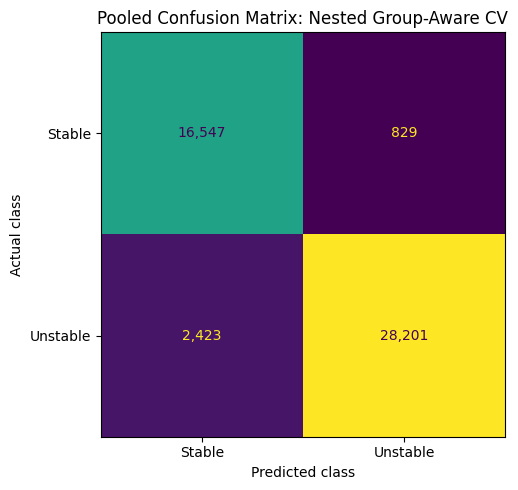

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=pooled_cm,
    display_labels=["Stable", "Unstable"]
)

display.plot(
    ax=ax,
    values_format=",d",
    colorbar=False
)

ax.set_title(
    "Pooled Confusion Matrix: Nested Group-Aware CV"
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()

plt.savefig(
    "nested_cv_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import json
import urllib.request

url = (
    "https://raw.githubusercontent.com/"
    "sabbirpuspo/smart-grid-stability-ml-benchmark/"
    "main/smart_grid_stability_ml_benchmark.ipynb"
)

try:
    with urllib.request.urlopen(url, timeout=30) as response:
        notebook = json.loads(response.read().decode("utf-8"))

    cells = notebook.get("cells", [])

    print("GitHub notebook loaded successfully.")
    print("Total cells:", len(cells))
    print("\n=== Last 12 cells in your saved GitHub notebook ===")

    start = max(0, len(cells) - 12)

    for i in range(start, len(cells)):
        cell = cells[i]
        source = "".join(cell.get("source", [])).strip()

        print(f"\n--- Cell {i + 1}: {cell['cell_type']} ---")
        print(source[:1200] if source else "[Empty cell]")

except Exception as error:
    print("Could not read the GitHub notebook:", repr(error))
    print("No model training was performed.")

GitHub notebook loaded successfully.
Total cells: 52

=== Last 12 cells in your saved GitHub notebook ===

--- Cell 41: code ---
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score
)

# Reuse the same five group-aware folds
fold_splits = list(
    cv.split(X_train, y_train, groups=groups_train)
)

feature_sets = {
    "11 features": list(X_train.columns),
    "8 features": tau_g_features
}

fold_results = []

for fold_number, (fit_idx, val_idx) in enumerate(
    fold_splits, start=1
):
    X_fit = X_train.iloc[fit_idx]
    X_val = X_train.iloc[val_idx]

    y_fit = y_train.iloc[fit_idx]
    y_val = y_train.iloc[val_idx]

    for model_name, features in feature_sets.items():

        model = RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fit[features], y_fit)

        predictions = mo

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/Smart_Grid_ML/Project_Results


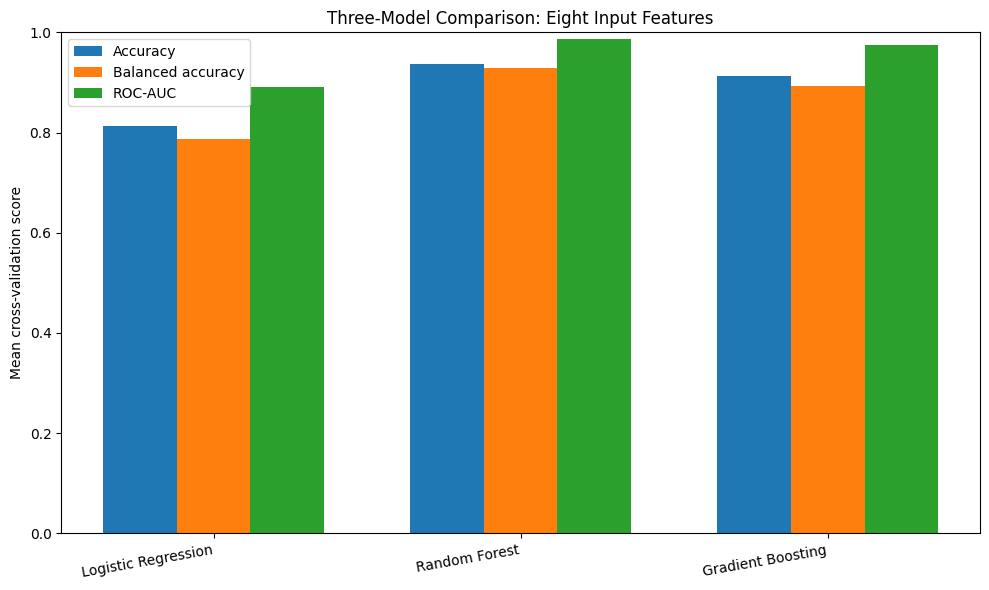

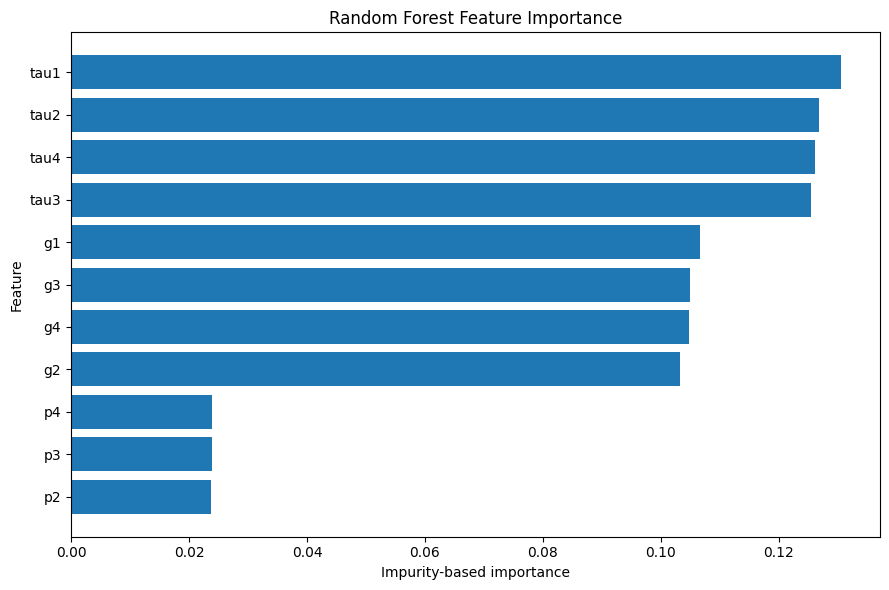

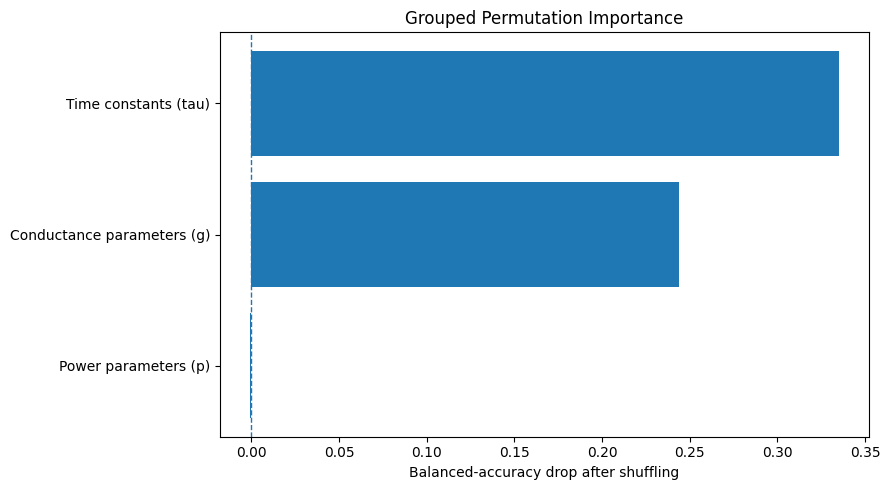

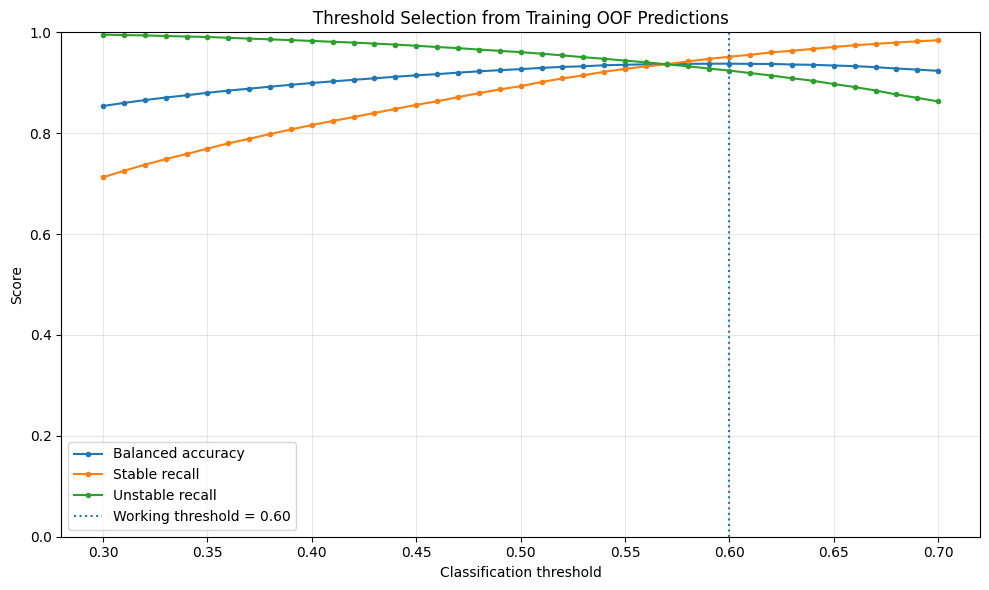

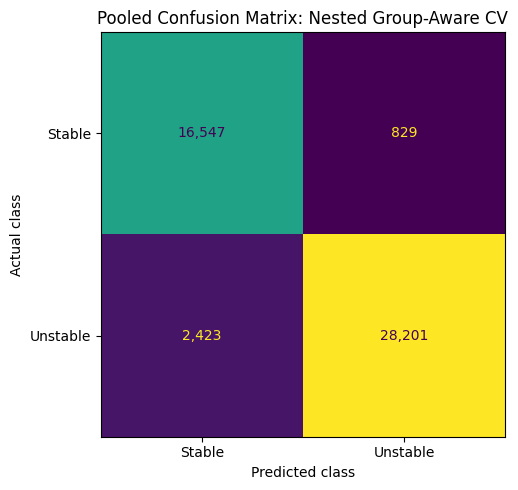


✅ FINAL RESULTS EXPORT COMPLETE
Report: /content/drive/MyDrive/Smart_Grid_ML/Project_Results/FINAL_RESULTS_REPORT.md
Figures: /content/drive/MyDrive/Smart_Grid_ML/Project_Results/figures
Tables: /content/drive/MyDrive/Smart_Grid_ML/Project_Results
Threshold data source: current 41-point threshold sweep
Pooled accuracy: 0.9322
Pooled balanced accuracy: 0.9366
No model training or cross-validation was run.


In [ ]:
# ============================================================
# CELL 53: FINAL RESULTS EXPORT
# No model training and no cross-validation reruns.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

# Save into your existing Google Drive project folder
OUT = Path("/content/drive/MyDrive/Smart_Grid_ML/Project_Results")
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUT)


# ------------------------------------------------------------
# 1. Prepare recorded results as fallbacks for runtime resets
# ------------------------------------------------------------

fallback_models = pd.DataFrame([
    ["Logistic Regression", .8121, .0159, .7874, .0166,
     .8902, .0102, .6979, .0241, .8770, .0187],
    ["Random Forest", .9367, .0081, .9280, .0096,
     .9872, .0023, .8963, .0174, .9596, .0069],
    ["Gradient Boosting", .9128, .0063, .8925, .0080,
     .9752, .0035, .8190, .0186, .9660, .0063]
], columns=[
    "Model", "accuracy mean", "accuracy std",
    "balanced_accuracy mean", "balanced_accuracy std",
    "roc_auc mean", "roc_auc std",
    "stable_recall mean", "stable_recall std",
    "unstable_recall mean", "unstable_recall std"
])

fallback_importance = pd.DataFrame({
    "Feature": [
        "tau1", "tau2", "tau4", "tau3",
        "g1", "g3", "g4", "g2", "p4", "p3", "p2"
    ],
    "Importance": [
        .1306, .1267, .1261, .1255,
        .1066, .1049, .1048, .1033, .0238, .0238, .0238
    ]
})

fallback_group = pd.DataFrame({
    "Feature family": [
        "Time constants (tau)",
        "Conductance parameters (g)",
        "Power parameters (p)"
    ],
    "Mean balanced-accuracy drop": [.3352, .2440, -.0010],
    "Standard deviation": [.0043, .0032, .0008]
})

fallback_thresholds = pd.DataFrame({
    "Threshold": [.30, .35, .40, .45, .50, .55, .60, .65, .70],
    "Balanced accuracy": [
        .8540, .8801, .8996, .9148, .9270,
        .9357, .9379, .9342, .9237
    ],
    "Stable recall": [
        .7126, .7695, .8161, .8562, .8933,
        .9275, .9517, .9709, .9843
    ],
    "Unstable recall": [
        .9954, .9907, .9830, .9734, .9608,
        .9440, .9241, .8975, .8630
    ]
})

fallback_nested = pd.DataFrame([
    [1, .61, .9357, .9418, .9892, .9640, .9195, 491, 126],
    [2, .60, .9424, .9447, .9879, .9528, .9365, 390, 163],
    [3, .60, .9399, .9404, .9879, .9423, .9386, 381, 196],
    [4, .60, .9265, .9317, .9859, .9501, .9132, 534, 172],
    [5, .62, .9168, .9239, .9832, .9519, .8959, 627, 172]
], columns=[
    "Fold", "Selected threshold", "Accuracy", "Balanced accuracy",
    "ROC-AUC", "Stable recall", "Unstable recall",
    "Unstable cases missed", "False alarms"
])


def existing_or_fallback(name, fallback):
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame) and not obj.empty:
        return obj.copy(), "current notebook variable: " + name
    return fallback.copy(), "recorded results from previous session"


models_df, source_models = existing_or_fallback(
    "model_comparison", fallback_models
)

importance_df, source_importance = existing_or_fallback(
    "importance_df", fallback_importance
)

group_df, source_group = existing_or_fallback(
    "group_importance_df", fallback_group
)

nested_df, source_nested = existing_or_fallback(
    "nested_df", fallback_nested
)

# Prefer the full 41-point threshold curve if it is still in memory.
if isinstance(globals().get("fine_threshold_df"), pd.DataFrame):
    threshold_df = fine_threshold_df.copy()
    source_threshold = "current 41-point threshold sweep"
elif isinstance(globals().get("threshold_df"), pd.DataFrame):
    threshold_df = threshold_df.copy()
    source_threshold = "recorded nine-point threshold table"
else:
    threshold_df = fallback_thresholds.copy()
    source_threshold = "recorded nine-point threshold table"

# Use the actual pooled matrix if available; otherwise use the
# numerical result already confirmed in our session.
pooled_matrix = np.asarray(
    globals().get("pooled_cm", [[16547, 829], [2423, 28201]]),
    dtype=int
)

assert pooled_matrix.shape == (2, 2)


# ------------------------------------------------------------
# 2. Save numerical tables
# ------------------------------------------------------------

tables = {
    "three_model_group_cv.csv": models_df,
    "random_forest_feature_importance.csv": importance_df,
    "grouped_permutation_importance.csv": group_df,
    "threshold_analysis.csv": threshold_df,
    "nested_group_cv_fold_metrics.csv": nested_df,
    "pooled_confusion_matrix.csv": pd.DataFrame(
        pooled_matrix,
        index=["Actual stable", "Actual unstable"],
        columns=["Predicted stable", "Predicted unstable"]
    ).rename_axis("Actual class").reset_index()
}

for filename, frame in tables.items():
    frame.to_csv(OUT / filename, index=False)


# ------------------------------------------------------------
# 3. Generate the four main research figures
# ------------------------------------------------------------

# Figure 1: Three-model comparison
metrics = [
    ("accuracy mean", "Accuracy"),
    ("balanced_accuracy mean", "Balanced accuracy"),
    ("roc_auc mean", "ROC-AUC")
]
metrics = [(c, label) for c, label in metrics if c in models_df.columns]

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(models_df))
width = .24

for i, (column, label) in enumerate(metrics):
    offset = (i - (len(metrics) - 1) / 2) * width
    ax.bar(x + offset, models_df[column], width, label=label)

ax.set_xticks(x)
ax.set_xticklabels(models_df["Model"], rotation=10, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Mean cross-validation score")
ax.set_title("Three-Model Comparison: Eight Input Features")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "three_model_comparison.png", dpi=300)
plt.show()
plt.close(fig)


# Figure 2: Original 11-feature Random Forest importance
imp_plot = importance_df.sort_values("Importance")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp_plot["Feature"], imp_plot["Importance"])
ax.set_xlabel("Impurity-based importance")
ax.set_ylabel("Feature")
ax.set_title("Random Forest Feature Importance")
fig.tight_layout()
fig.savefig(FIG / "feature_importance.png", dpi=300)
plt.show()
plt.close(fig)


# Figure 3: Grouped permutation importance
group_plot = group_df.sort_values("Mean balanced-accuracy drop")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    group_plot["Feature family"],
    group_plot["Mean balanced-accuracy drop"]
)
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Balanced-accuracy drop after shuffling")
ax.set_title("Grouped Permutation Importance")
fig.tight_layout()
fig.savefig(FIG / "grouped_permutation_importance.png", dpi=300)
plt.show()
plt.close(fig)


# Figure 4: Threshold trade-off
fig, ax = plt.subplots(figsize=(10, 6))

for column, label in [
    ("Balanced accuracy", "Balanced accuracy"),
    ("Stable recall", "Stable recall"),
    ("Unstable recall", "Unstable recall")
]:
    if column in threshold_df.columns:
        ax.plot(
            threshold_df["Threshold"],
            threshold_df[column],
            marker="o",
            markersize=3,
            label=label
        )

ax.axvline(.60, linestyle=":", label="Working threshold = 0.60")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Threshold Selection from Training OOF Predictions")
ax.grid(True, alpha=.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "threshold_tradeoff.png", dpi=300)
plt.show()
plt.close(fig)


# Figure 5: Pooled outer-fold confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))
display = ConfusionMatrixDisplay(
    confusion_matrix=pooled_matrix,
    display_labels=["Stable", "Unstable"]
)
display.plot(ax=ax, values_format=",d", colorbar=False)
ax.set_title("Pooled Confusion Matrix: Nested Group-Aware CV")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
fig.tight_layout()
fig.savefig(FIG / "nested_cv_confusion_matrix.png", dpi=300)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 4. Calculate and save the final report
# ------------------------------------------------------------

tn, fp = pooled_matrix[0]
fn, tp = pooled_matrix[1]
total = pooled_matrix.sum()

stable_recall = tn / (tn + fp)
unstable_recall = tp / (tp + fn)
accuracy = (tn + tp) / total
balanced_accuracy = (stable_recall + unstable_recall) / 2

mean_nested = nested_df[
    ["Accuracy", "Balanced accuracy", "ROC-AUC",
     "Stable recall", "Unstable recall"]
].mean()

mean_threshold = nested_df["Selected threshold"].mean()
median_threshold = nested_df["Selected threshold"].median()


def to_markdown(frame):
    """Create Markdown tables without an additional dependency."""
    frame = frame.copy()
    headers = [str(c) for c in frame.columns]
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    for _, row in frame.iterrows():
        values = []
        for value in row:
            if isinstance(value, (float, np.floating)):
                values.append(f"{value:.4f}")
            else:
                values.append(str(value))
        lines.append("| " + " | ".join(values) + " |")

    return "\n".join(lines)


model_columns = [
    c for c in [
        "Model", "accuracy mean", "balanced_accuracy mean",
        "roc_auc mean", "stable_recall mean", "unstable_recall mean"
    ] if c in models_df.columns
]

report = f"""# Smart Grid Stability Prediction — Final Results

## Dataset and features

The dataset contains 60,000 rows representing 10,000 canonical configurations,
with six consumer-node permutations per configuration. We used group-aware
splits to keep permutations of the same configuration together.

The final reduced Random Forest uses eight inputs: `tau1`, `tau2`, `tau3`,
`tau4`, `g1`, `g2`, `g3`, and `g4`.

The feature `stab` was excluded because it perfectly determines the target
label in this dataset. The feature `p1` was excluded after verifying that
`p1 = abs(p2 + p3 + p4)`.

## Three-model comparison

{to_markdown(models_df[model_columns])}

Random Forest was the strongest overall candidate in the initial
five-fold group-aware comparison. Gradient Boosting had slightly higher
unstable-class recall, while Random Forest had higher stable-class recall.

## Feature importance

{to_markdown(importance_df)}

These are impurity-based importance scores from the original Random Forest.
They describe how that fitted model uses features; they do not establish
physical causality.

## Grouped permutation importance

{to_markdown(group_df)}

The near-zero score for the power-feature family indicates little dependence
of this particular fitted model on those features under the chosen
permutation procedure. It does not mean power variables are physically
unimportant.

## Threshold analysis

Threshold source used: {source_threshold}.

Balanced accuracy was the primary threshold-selection criterion, giving
stable and unstable recall equal weight. The working candidate threshold is
0.60. Within nested validation, selected thresholds had a mean of
{mean_threshold:.3f} and a median of {median_threshold:.2f}.

## Nested group-aware cross-validation

| Metric | Mean across outer folds |
|---|---:|
| Accuracy | {mean_nested["Accuracy"]:.4f} |
| Balanced accuracy | {mean_nested["Balanced accuracy"]:.4f} |
| ROC-AUC | {mean_nested["ROC-AUC"]:.4f} |
| Stable recall | {mean_nested["Stable recall"]:.4f} |
| Unstable recall | {mean_nested["Unstable recall"]:.4f} |

## Pooled outer-fold confusion matrix

Actual rows and predicted columns are ordered Stable, Unstable.

| Actual class | Predicted stable | Predicted unstable |
|---|---:|---:|
| Stable | {tn:,} correct | {fp:,} false alarms |
| Unstable | {fn:,} missed cases | {tp:,} correct |

Pooled accuracy: **{accuracy:.4f}**.

Pooled balanced accuracy: **{balanced_accuracy:.4f}**.

Stable recall: **{stable_recall:.4f}**.

Unstable recall: **{unstable_recall:.4f}**.

**Figure caption:** Pooled confusion matrix for the eight-feature Random Forest
using nested group-aware cross-validation. The threshold was selected within
each outer training fold. The matrix summarizes predictions on held-out
configuration groups from the development dataset.

## Limitations

1. Results are based on a simulated dataset; independent external validation
   is needed before claiming performance on real-world electrical grids.
2. Earlier model and feature selection involved exploratory comparisons,
   including repeated use of the original test set. The nested evaluation
   assesses threshold selection conditional on the chosen model, but does not
   remove all previous model-selection bias.
3. The threshold of 0.60 is a working candidate for balanced accuracy, not a
   universally optimal operational threshold.
4. Feature importance is not causal evidence.

## Reproducibility note

The numerical tables and figures were reconstructed from current notebook
variables when available, otherwise from the recorded results in the
development session. This export cell does not train models or rerun CV.
"""


report_path = OUT / "FINAL_RESULTS_REPORT.md"
report_path.write_text(report, encoding="utf-8")

manifest = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "output_directory": str(OUT),
    "pooled_confusion_matrix": pooled_matrix.tolist(),
    "pooled_accuracy": float(accuracy),
    "pooled_balanced_accuracy": float(balanced_accuracy),
    "mean_nested_threshold": float(mean_threshold),
    "median_nested_threshold": float(median_threshold),
    "threshold_table_source": source_threshold,
    "result_sources": {
        "three_model_comparison": source_models,
        "feature_importance": source_importance,
        "grouped_permutation": source_group,
        "nested_cv": source_nested
    },
    "note": "Export only; no model training or CV was run."
}

(OUT / "results_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("\n✅ FINAL RESULTS EXPORT COMPLETE")
print("Report:", report_path)
print("Figures:", FIG)
print("Tables:", OUT)
print("Threshold data source:", source_threshold)
print("Pooled accuracy:", round(accuracy, 4))
print("Pooled balanced accuracy:", round(balanced_accuracy, 4))
print("No model training or cross-validation was run.")

In [ ]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Smart_Grid_ML/Project_Results"
)

print("=== Saved Project Results ===")

for path in sorted(output_dir.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(output_dir)}  |  {path.stat().st_size:,} bytes")

print("\nTotal files:", sum(
    1 for path in output_dir.rglob("*") if path.is_file()
))

=== Saved Project Results ===
FINAL_RESULTS_REPORT.md  |  4,155 bytes
figures/feature_importance.png  |  86,639 bytes
figures/grouped_permutation_importance.png  |  93,626 bytes
figures/nested_cv_confusion_matrix.png  |  88,530 bytes
figures/three_model_comparison.png  |  150,475 bytes
figures/threshold_tradeoff.png  |  190,020 bytes
grouped_permutation_importance.csv  |  259 bytes
nested_group_cv_fold_metrics.csv  |  661 bytes
pooled_confusion_matrix.csv  |  100 bytes
random_forest_feature_importance.csv  |  280 bytes
results_manifest.json  |  818 bytes
three_model_group_cv.csv  |  821 bytes
threshold_analysis.csv  |  2,575 bytes

Total files: 13


In [ ]:
# ============================================================
# RESTORE DATASET FOR THE NEW PCSF ALGORITHM
# No model training is performed here.
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd

# Mount Drive (safe if it is already mounted)
drive.mount("/content/drive", force_remount=False)

# Check your known dataset locations
candidate_paths = [
    Path("/content/drive/MyDrive/Smart_Grid_ML/smart_grid_stability_augmented.csv"),
    Path("/content/drive/MyDrive/Smart Grid Stability Dataset/smart_grid_stability_augmented.csv")
]

file_path = next(
    (path for path in candidate_paths if path.is_file()),
    None
)

# If neither expected location exists, search MyDrive for the filename
if file_path is None:
    matches = list(
        Path("/content/drive/MyDrive").rglob(
            "smart_grid_stability_augmented.csv"
        )
    )
    if matches:
        file_path = matches[0]

if file_path is None:
    raise FileNotFoundError(
        "Could not find smart_grid_stability_augmented.csv in Google Drive. "
        "Please check the filename and Drive folder."
    )

# Restore the dataset variable
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("File:", file_path)
print("Dataset shape:", df.shape)
print("Required target column present:", "stabf" in df.columns)
print("Missing values:", int(df.isna().sum().sum()))

assert df.shape == (60000, 14), (
    f"Unexpected dataset shape: {df.shape}. Please inspect the CSV."
)
assert "stabf" in df.columns, "Target column 'stabf' is missing."
assert df["stabf"].notna().all(), "Target labels contain missing values."

Mounted at /content/drive
Dataset loaded successfully!
File: /content/drive/MyDrive/Smart Grid Stability Dataset/smart_grid_stability_augmented.csv
Dataset shape: (60000, 14)
Required target column present: True
Missing values: 0


In [ ]:
# ============================================================
# NEW ALGORITHM — EXPERIMENT 1
# Permutation-Canonicalized Stability Forest (PCSF)
# Step 1: Verify symmetry and data compression
# ============================================================

import numpy as np
import pandas as pd

# These variables should already exist in your current notebook.
assert "df" in globals(), (
    "Dataset df is not in memory. Load the CSV first."
)

assert len(df) == 60000, (
    f"Expected 60,000 rows, found {len(df)}."
)

# Reconstruct group IDs only if they are missing.
# This does not train a model.
if "group_ids" not in globals() or len(group_ids) != len(df):

    def full_configuration_key(row):
        consumer_nodes = sorted([
            (
                round(row[f"tau{i}"], 8),
                round(row[f"p{i}"], 8),
                round(row[f"g{i}"], 8)
            )
            for i in [2, 3, 4]
        ])

        return (
            round(row["tau1"], 8),
            round(row["p1"], 8),
            round(row["g1"], 8),
            tuple(consumer_nodes)
        )

    group_keys = df.apply(full_configuration_key, axis=1)
    group_ids = pd.factorize(group_keys)[0]

# Model inputs: 11 predictive features.
# p1 is excluded because we verified that it is redundant.
input_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

canonical_columns = [
    "tau1", "g1",
    "consumer1_tau", "consumer1_p", "consumer1_g",
    "consumer2_tau", "consumer2_p", "consumer2_g",
    "consumer3_tau", "consumer3_p", "consumer3_g"
]


def canonicalize_consumer_nodes(frame):
    """
    Sort the three consumer-node parameter triples.
    Equivalent permutations then produce the same input vector.
    """

    canonical_rows = []

    for values in frame[input_columns].itertuples(
        index=False, name=None
    ):
        (
            tau1, tau2, tau3, tau4,
            p2, p3, p4,
            g1, g2, g3, g4
        ) = values

        # Keep each consumer's tau, p and g values together.
        consumers = sorted([
            (tau2, p2, g2),
            (tau3, p3, g3),
            (tau4, p4, g4)
        ])

        # Producer parameters followed by sorted consumers.
        canonical_row = [tau1, g1]

        for consumer in consumers:
            canonical_row.extend(consumer)

        canonical_rows.append(canonical_row)

    return pd.DataFrame(
        canonical_rows,
        columns=canonical_columns,
        index=frame.index
    )


# Canonicalize the 60,000 dataset rows.
X_pcsf_all = canonicalize_consumer_nodes(df)

# Check that groups have consistent labels.
group_check = pd.DataFrame({
    "group_id": np.asarray(group_ids),
    "target": df["stabf"].to_numpy()
})

labels_per_group = (
    group_check.groupby("group_id")["target"].nunique()
)

# Check whether all permutations in a group become identical.
invariance_check = X_pcsf_all.copy()
invariance_check["_group_id"] = np.asarray(group_ids)

distinct_values_per_group = (
    invariance_check
    .groupby("_group_id")[canonical_columns]
    .nunique()
)

is_permutation_invariant = (
    distinct_values_per_group.to_numpy().max() == 1
)

# Select one representative row per configuration.
representatives = (
    pd.DataFrame({
        "group_id": np.asarray(group_ids),
        "row_index": np.arange(len(df)),
        "target": df["stabf"].to_numpy()
    })
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)

X_pcsf_unique = (
    X_pcsf_all.iloc[representatives["row_index"]]
    .reset_index(drop=True)
)

y_pcsf_unique = representatives["target"].reset_index(drop=True)

print("=== PCSF: Permutation and Compression Checks ===")
print("Original dataset rows:", len(df))
print("Unique physical configurations:", len(representatives))
print("Canonical features per configuration:", len(canonical_columns))

print(
    "Rows per configuration:",
    pd.Series(group_ids).value_counts().value_counts().sort_index().to_dict()
)

print("Every group has a consistent target:",
      bool((labels_per_group == 1).all()))

print("Permutation invariance verified:",
      is_permutation_invariant)

print("Unique configurations after canonicalization:",
      len(X_pcsf_unique))

print(
    "Row-count reduction: "
    f"{100 * (1 - len(X_pcsf_unique) / len(df)):.2f}%"
)

print("\nCanonical feature matrix:", X_pcsf_unique.shape)
print("Canonical target vector:", y_pcsf_unique.shape)

=== PCSF: Permutation and Compression Checks ===
Original dataset rows: 60000
Unique physical configurations: 10000
Canonical features per configuration: 11
Rows per configuration: {6: 10000}
Every group has a consistent target: True
Permutation invariance verified: True
Unique configurations after canonicalization: 10000
Row-count reduction: 83.33%

Canonical feature matrix: (10000, 11)
Canonical target vector: (10000,)


In [ ]:
# ============================================================
# PCSF EXPERIMENT 2
# Compare canonicalized Random Forest against raw-data baselines
# ============================================================

import time
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    roc_auc_score,
    confusion_matrix,
    f1_score
)

# ------------------------------------------------------------
# 1. Validate the objects from the previous PCSF experiment
# ------------------------------------------------------------

assert "df" in globals(), "Dataset df is missing; load your CSV first."
assert len(df) == 60000, f"Unexpected dataset size: {df.shape}"

# Input features for the original Random Forest baselines.
# p1 and stab are excluded.
raw_11_features = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

raw_8_features = [
    "tau1", "tau2", "tau3", "tau4",
    "g1", "g2", "g3", "g4"
]

canonical_columns = [
    "tau1", "g1",
    "consumer1_tau", "consumer1_p", "consumer1_g",
    "consumer2_tau", "consumer2_p", "consumer2_g",
    "consumer3_tau", "consumer3_p", "consumer3_g"
]

# Recover group IDs if the runtime has lost them.
if "group_ids" not in globals() or len(group_ids) != len(df):

    def configuration_key(row):
        consumers = sorted([
            (round(row["tau2"], 8),
             round(row["p2"], 8),
             round(row["g2"], 8)),
            (round(row["tau3"], 8),
             round(row["p3"], 8),
             round(row["g3"], 8)),
            (round(row["tau4"], 8),
             round(row["p4"], 8),
             round(row["g4"], 8))
        ])

        return (
            round(row["tau1"], 8),
            round(row["p1"], 8),
            round(row["g1"], 8),
            tuple(consumers)
        )

    group_keys = df.apply(configuration_key, axis=1)
    group_ids = pd.factorize(group_keys)[0]

group_ids = np.asarray(group_ids)

assert len(group_ids) == len(df)

# Build canonical inputs only if they are no longer in memory.
if (
    "X_pcsf_all" not in globals()
    or not isinstance(X_pcsf_all, pd.DataFrame)
    or len(X_pcsf_all) != len(df)
    or not set(canonical_columns).issubset(X_pcsf_all.columns)
):

    def build_canonical_inputs(frame):
        rows = []

        for values in frame[raw_11_features].itertuples(
            index=False, name=None
        ):
            tau1, tau2, tau3, tau4, p2, p3, p4, g1, g2, g3, g4 = values

            consumers = sorted([
                (tau2, p2, g2),
                (tau3, p3, g3),
                (tau4, p4, g4)
            ])

            row = [tau1, g1]
            for consumer in consumers:
                row.extend(consumer)

            rows.append(row)

        return pd.DataFrame(
            rows, columns=canonical_columns, index=frame.index
        )

    X_pcsf_all = build_canonical_inputs(df)

# Rebuild one row per group in a deterministic order.
representatives = (
    pd.DataFrame({
        "group_id": group_ids,
        "row_index": np.arange(len(df)),
        "target": df["stabf"].to_numpy()
    })
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)

group_sizes = pd.Series(group_ids).value_counts()

assert len(representatives) == 10000
assert (group_sizes == 6).all()

label_counts = (
    pd.DataFrame({
        "group_id": group_ids,
        "target": df["stabf"].to_numpy()
    })
    .groupby("group_id")["target"]
    .nunique()
)

assert (label_counts == 1).all(), "A configuration has inconsistent labels."

X_canonical_unique = (
    X_pcsf_all.iloc[representatives["row_index"].to_numpy()]
    [canonical_columns]
    .reset_index(drop=True)
)

y_canonical_unique = representatives["target"].reset_index(drop=True)
canonical_group_ids = representatives["group_id"].to_numpy()

# ------------------------------------------------------------
# 2. Create one shared, stratified configuration split
# ------------------------------------------------------------

group_table = representatives[["group_id", "target"]].copy()

train_group_ids, test_group_ids = train_test_split(
    group_table["group_id"].to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=group_table["target"]
)

raw_train_mask = np.isin(group_ids, train_group_ids)
raw_test_mask = np.isin(group_ids, test_group_ids)

canonical_train_mask = np.isin(
    canonical_group_ids, train_group_ids
)
canonical_test_mask = np.isin(
    canonical_group_ids, test_group_ids
)

assert len(train_group_ids) == 8000
assert len(test_group_ids) == 2000
assert raw_train_mask.sum() == 48000
assert raw_test_mask.sum() == 12000
assert canonical_train_mask.sum() == 8000
assert canonical_test_mask.sum() == 2000

print("Shared group split verified:")
print("Training configurations:", len(train_group_ids))
print("Testing configurations:", len(test_group_ids))
print("Raw training rows:", int(raw_train_mask.sum()))
print("Canonical training rows:", int(canonical_train_mask.sum()))

# ------------------------------------------------------------
# 3. Train the two raw-data Random Forest baselines
# ------------------------------------------------------------

def train_random_forest(model_name, features, train_mask, test_mask):
    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    X_train_part = df.loc[train_mask, features]
    y_train_part = df.loc[train_mask, "stabf"]
    X_test_part = df.loc[test_mask, features]

    start = time.perf_counter()
    model.fit(X_train_part, y_train_part)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    probabilities = model.predict_proba(X_test_part)
    predict_seconds = time.perf_counter() - start

    unstable_index = list(model.classes_).index("unstable")
    unstable_probabilities = probabilities[:, unstable_index]

    print(
        f"{model_name}: trained on {len(X_train_part):,} rows "
        f"in {fit_seconds:.1f} seconds."
    )

    return model, unstable_probabilities, fit_seconds, predict_seconds


rf_raw_11, prob_raw_11, time_raw_11, predict_raw_11 = (
    train_random_forest(
        "Raw RF (11 features)",
        raw_11_features,
        raw_train_mask,
        raw_test_mask
    )
)

rf_raw_8, prob_raw_8, time_raw_8, predict_raw_8 = (
    train_random_forest(
        "Raw RF (8 features)",
        raw_8_features,
        raw_train_mask,
        raw_test_mask
    )
)

# ------------------------------------------------------------
# 4. Train PCSF: one canonical row per training configuration
# ------------------------------------------------------------

pcsf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

X_pc_train = X_canonical_unique.iloc[
    np.flatnonzero(canonical_train_mask)
]
y_pc_train = y_canonical_unique.iloc[
    np.flatnonzero(canonical_train_mask)
]
X_pc_test = X_canonical_unique.iloc[
    np.flatnonzero(canonical_test_mask)
]

start = time.perf_counter()
pcsf_model.fit(X_pc_train, y_pc_train)
time_pcsf = time.perf_counter() - start

start = time.perf_counter()
pcsf_probabilities = pcsf_model.predict_proba(X_pc_test)
predict_pcsf = time.perf_counter() - start

pcsf_unstable_index = list(pcsf_model.classes_).index("unstable")
prob_pcsf = pcsf_probabilities[:, pcsf_unstable_index]

print(
    f"PCSF: trained on {len(X_pc_train):,} canonical rows "
    f"in {time_pcsf:.1f} seconds."
)

# ------------------------------------------------------------
# 5. Aggregate each raw baseline's six test predictions
# ------------------------------------------------------------

def average_permutation_probabilities(probabilities, test_mask, name):
    frame = pd.DataFrame({
        "group_id": group_ids[test_mask],
        "probability": probabilities
    })

    aggregated = (
        frame.groupby("group_id")
        .agg(
            probability=("probability", "mean"),
            permutation_count=("probability", "size")
        )
        .reset_index()
    )

    assert (aggregated["permutation_count"] == 6).all(), (
        f"{name}: expected six test permutations per group."
    )

    return aggregated[["group_id", "probability"]].rename(
        columns={"probability": name}
    )


raw_11_group_probs = average_permutation_probabilities(
    prob_raw_11, raw_test_mask, "Raw RF 11 probability"
)

raw_8_group_probs = average_permutation_probabilities(
    prob_raw_8, raw_test_mask, "Raw RF 8 probability"
)

pcsf_group_probs = pd.DataFrame({
    "group_id": canonical_group_ids[canonical_test_mask],
    "PCSF probability": prob_pcsf
})

test_truth = (
    group_table[group_table["group_id"].isin(test_group_ids)]
    .rename(columns={"target": "Actual label"})
    [["group_id", "Actual label"]]
)

evaluation = (
    test_truth
    .merge(raw_11_group_probs, on="group_id", validate="one_to_one")
    .merge(raw_8_group_probs, on="group_id", validate="one_to_one")
    .merge(pcsf_group_probs, on="group_id", validate="one_to_one")
    .sort_values("group_id")
    .reset_index(drop=True)
)

assert len(evaluation) == 2000

# ------------------------------------------------------------
# 6. Compare accuracy, balanced accuracy, recall, ROC-AUC,
#    false alarms, missed unstable cases, and training time.
#    Thresholds 0.50 and 0.60 are both shown.
# ------------------------------------------------------------

model_specs = [
    ("Raw RF (11 features)", "Raw RF 11 probability",
     int(raw_train_mask.sum()), 11, time_raw_11, predict_raw_11, 12000),
    ("Raw RF (8 features)", "Raw RF 8 probability",
     int(raw_train_mask.sum()), 8, time_raw_8, predict_raw_8, 12000),
    ("PCSF (11 canonical features)", "PCSF probability",
     int(canonical_train_mask.sum()), 11, time_pcsf, predict_pcsf, 2000)
]

y_true = evaluation["Actual label"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

comparison_rows = []

for name, probability_column, training_rows, n_features, fit_time, pred_time, scored_rows in model_specs:
    probabilities = evaluation[probability_column].to_numpy()
    auc = roc_auc_score(y_binary, probabilities)

    for threshold in [0.50, 0.60]:
        predictions = np.where(
            probabilities >= threshold,
            "unstable",
            "stable"
        )

        cm = confusion_matrix(
            y_true,
            predictions,
            labels=["stable", "unstable"]
        )

        comparison_rows.append({
            "Method": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_true, predictions),
            "Balanced accuracy": balanced_accuracy_score(
                y_true, predictions
            ),
            "ROC-AUC": auc,
            "Macro F1": f1_score(
                y_true, predictions, average="macro"
            ),
            "Stable recall": recall_score(
                y_true, predictions, pos_label="stable"
            ),
            "Unstable recall": recall_score(
                y_true, predictions, pos_label="unstable"
            ),
            "Unstable precision": precision_score(
                y_true, predictions, pos_label="unstable"
            ),
            "Unstable cases missed": int(cm[1, 0]),
            "False alarms": int(cm[0, 1]),
            "Training rows": training_rows,
            "Training configurations": len(train_group_ids),
            "Input features": n_features,
            "Fit seconds": fit_time,
            "Prediction rows": scored_rows,
            "Prediction seconds": pred_time
        })

pcsf_comparison = pd.DataFrame(comparison_rows)

print("\n=== PCSF vs. Raw Random Forest Baselines ===")
print(pcsf_comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# 7. Save the results and PCSF model to Google Drive
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Smart_Grid_ML/Project_Results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pcsf_comparison.to_csv(
    OUTPUT_DIR / "PCSF_vs_RandomForest_baselines.csv",
    index=False
)

evaluation.to_csv(
    OUTPUT_DIR / "PCSF_test_configuration_probabilities.csv",
    index=False
)

joblib.dump(
    pcsf_model,
    OUTPUT_DIR / "PCSF_random_forest_model.joblib"
)

metadata = {
    "algorithm": "PCSF prototype: permutation-canonicalized Random Forest",
    "original_rows": int(len(df)),
    "unique_configurations": int(len(representatives)),
    "permutations_per_configuration": 6,
    "train_configurations": int(len(train_group_ids)),
    "test_configurations": int(len(test_group_ids)),
    "pcsf_training_rows": int(len(X_pc_train)),
    "raw_baseline_training_rows": int(raw_train_mask.sum()),
    "trees": 300,
    "thresholds_evaluated": [0.50, 0.60],
    "evaluation_unit": "physical configuration; raw probabilities averaged across six permutations",
    "warning": "Exploratory comparison on a previously inspected development split; not an independent final evaluation."
}

(OUTPUT_DIR / "PCSF_experiment_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

print("\nPCSF experiment completed.")
print("Comparison saved to:", OUTPUT_DIR / "PCSF_vs_RandomForest_baselines.csv")
print("PCSF model saved to:", OUTPUT_DIR / "PCSF_random_forest_model.joblib")
print("No nested cross-validation was rerun.")

Shared group split verified:
Training configurations: 8000
Testing configurations: 2000
Raw training rows: 48000
Canonical training rows: 8000
Raw RF (11 features): trained on 48,000 rows in 40.9 seconds.
Raw RF (8 features): trained on 48,000 rows in 28.0 seconds.
PCSF: trained on 8,000 canonical rows in 6.2 seconds.

=== PCSF vs. Raw Random Forest Baselines ===
                      Method  Threshold  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unstable precision  Unstable cases missed  False alarms  Training rows  Training configurations  Input features  Fit seconds  Prediction rows  Prediction seconds
        Raw RF (11 features)        0.5    0.9355             0.9264   0.9882    0.9296         0.8936           0.9592              0.9408                     52            77          48000                     8000              11      40.9165            12000              0.4295
        Raw RF (11 features)        0.6    0.9370             0.9420

In [ ]:
# ============================================================
# PCSF EXPERIMENT 3: 3-FOLD GROUP-LEVEL COMPARISON
# Uses all 10,000 configurations for out-of-fold evaluation.
# Does not rerun nested CV or hyperparameter tuning.
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# Recover canonical inputs if needed.
raw11 = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4", "g1", "g2", "g3", "g4"
]
raw8 = [
    "tau1", "tau2", "tau3", "tau4",
    "g1", "g2", "g3", "g4"
]
canonical_cols = [
    "tau1", "g1",
    "consumer1_tau", "consumer1_p", "consumer1_g",
    "consumer2_tau", "consumer2_p", "consumer2_g",
    "consumer3_tau", "consumer3_p", "consumer3_g"
]

group_arr = np.asarray(group_ids)

representatives = (
    pd.DataFrame({
        "group_id": group_arr,
        "row_index": np.arange(len(df)),
        "target": df["stabf"].to_numpy()
    })
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)

group_sizes = pd.Series(group_arr).value_counts()
assert (group_sizes == 6).all()
assert len(representatives) == 10000

if (
    "X_pcsf_all" not in globals()
    or not isinstance(X_pcsf_all, pd.DataFrame)
    or len(X_pcsf_all) != len(df)
    or not set(canonical_cols).issubset(X_pcsf_all.columns)
):
    def canonicalize(frame):
        output = []
        for vals in frame[raw11].itertuples(index=False, name=None):
            t1, t2, t3, t4, p2, p3, p4, g1, g2, g3, g4 = vals
            nodes = sorted([(t2, p2, g2), (t3, p3, g3), (t4, p4, g4)])
            output.append([t1, g1] + [v for node in nodes for v in node])
        return pd.DataFrame(output, columns=canonical_cols, index=frame.index)

    X_pcsf_all = canonicalize(df)

X_unique = (
    X_pcsf_all.iloc[representatives["row_index"].to_numpy()]
    [canonical_cols]
    .reset_index(drop=True)
)
y_unique = representatives["target"].reset_index(drop=True)
group_table = representatives[["group_id", "target"]].copy()

assert len(X_unique) == len(y_unique) == 10000

# Split physical configurations, not the individual permutation rows.
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=2026)

prediction_records = []
timing_records = []

for fold, (tr_pos, va_pos) in enumerate(
    cv3.split(X_unique, y_unique), start=1
):
    print(f"\nFold {fold}/3")

    train_gids = group_table.iloc[tr_pos]["group_id"].to_numpy()
    valid_gids = group_table.iloc[va_pos]["group_id"].to_numpy()

    raw_train_mask = np.isin(group_arr, train_gids)
    raw_valid_mask = np.isin(group_arr, valid_gids)

    assert not np.intersect1d(train_gids, valid_gids).size

    # Truth: exactly one label per held-out physical configuration.
    fold_truth = (
        group_table.iloc[va_pos][["group_id", "target"]]
        .rename(columns={"target": "Actual"})
        .copy()
    )

    fold_record = fold_truth.copy()

    # Train raw 11-feature and raw 8-feature baselines.
    for method_name, features, prob_col in [
        ("Raw RF 11", raw11, "P_raw11"),
        ("Raw RF 8", raw8, "P_raw8")
    ]:
        model = RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )

        start = time.perf_counter()
        model.fit(
            df.loc[raw_train_mask, features],
            df.loc[raw_train_mask, "stabf"]
        )
        fit_seconds = time.perf_counter() - start

        start = time.perf_counter()
        raw_prob = model.predict_proba(df.loc[raw_valid_mask, features])
        predict_seconds = time.perf_counter() - start

        unstable_idx = list(model.classes_).index("unstable")
        row_probs = raw_prob[:, unstable_idx]

        # Average six permutation probabilities into one configuration.
        aggregated = pd.DataFrame({
            "group_id": group_arr[raw_valid_mask],
            prob_col: row_probs
        }).groupby("group_id", as_index=False)[prob_col].mean()

        assert len(aggregated) == len(va_pos)
        fold_record = fold_record.merge(
            aggregated, on="group_id", validate="one_to_one"
        )

        timing_records.append({
            "Fold": fold,
            "Method": method_name,
            "Training rows": int(raw_train_mask.sum()),
            "Fit seconds": fit_seconds,
            "Prediction rows": int(raw_valid_mask.sum()),
            "Prediction seconds": predict_seconds
        })

        print(
            f"{method_name}: {fit_seconds:.1f}s fit, "
            f"{int(raw_train_mask.sum()):,} training rows"
        )

    # Train PCSF on the unique canonical configurations.
    pcsf = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    start = time.perf_counter()
    pcsf.fit(X_unique.iloc[tr_pos], y_unique.iloc[tr_pos])
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    pc_prob = pcsf.predict_proba(X_unique.iloc[va_pos])
    predict_seconds = time.perf_counter() - start

    unstable_idx = list(pcsf.classes_).index("unstable")

    fold_pcsf = pd.DataFrame({
        "group_id": group_table.iloc[va_pos]["group_id"].to_numpy(),
        "P_PCSF": pc_prob[:, unstable_idx]
    })

    fold_record = fold_record.merge(
        fold_pcsf, on="group_id", validate="one_to_one"
    )

    timing_records.append({
        "Fold": fold,
        "Method": "PCSF",
        "Training rows": len(tr_pos),
        "Fit seconds": fit_seconds,
        "Prediction rows": len(va_pos),
        "Prediction seconds": predict_seconds
    })

    print(
        f"PCSF: {fit_seconds:.1f}s fit, "
        f"{len(tr_pos):,} canonical training rows"
    )

    prediction_records.append(fold_record)

# Each configuration must receive exactly one out-of-fold prediction.
oof = pd.concat(prediction_records, ignore_index=True)

assert len(oof) == 10000
assert oof["group_id"].nunique() == 10000
assert not oof.isna().any().any()

y_true = oof["Actual"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

results = []

for method_name, prob_col in [
    ("Raw RF 11", "P_raw11"),
    ("Raw RF 8", "P_raw8"),
    ("PCSF", "P_PCSF")
]:
    probabilities = oof[prob_col].to_numpy()

    for threshold in [0.50, 0.60]:
        predicted = np.where(
            probabilities >= threshold, "unstable", "stable"
        )

        cm = confusion_matrix(
            y_true, predicted, labels=["stable", "unstable"]
        )

        results.append({
            "Method": method_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_true, predicted),
            "Balanced accuracy": balanced_accuracy_score(
                y_true, predicted
            ),
            "ROC-AUC": roc_auc_score(y_binary, probabilities),
            "Macro F1": f1_score(
                y_true, predicted, average="macro"
            ),
            "Stable recall": recall_score(
                y_true, predicted, pos_label="stable"
            ),
            "Unstable recall": recall_score(
                y_true, predicted, pos_label="unstable"
            ),
            "Unstable precision": precision_score(
                y_true, predicted, pos_label="unstable"
            ),
            "Unstable cases missed": int(cm[1, 0]),
            "False alarms": int(cm[0, 1])
        })

cv_results = pd.DataFrame(results)
timings = pd.DataFrame(timing_records)

print("\n=== 3-Fold Configuration-Level OOF Comparison ===")
print(cv_results.round(4).to_string(index=False))

print("\n=== Mean Training Time per Fold ===")
print(
    timings.groupby("Method")["Fit seconds"]
    .agg(["mean", "std"])
    .round(2)
    .to_string()
)

# Save artifacts to Drive.
out_dir = Path(
    "/content/drive/MyDrive/Smart_Grid_ML/Project_Results"
)
out_dir.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(
    out_dir / "PCSF_3fold_OOF_comparison.csv", index=False
)
timings.to_csv(
    out_dir / "PCSF_3fold_training_times.csv", index=False
)
oof.to_csv(
    out_dir / "PCSF_3fold_OOF_probabilities.csv", index=False
)

print("\nSaved 3-fold OOF results to:", out_dir)
print("No hyperparameter search or nested cross-validation was run.")


Fold 1/3
Raw RF 11: 22.3s fit, 39,996 training rows
Raw RF 8: 15.1s fit, 39,996 training rows
PCSF: 3.3s fit, 6,666 canonical training rows

Fold 2/3
Raw RF 11: 22.5s fit, 40,002 training rows
Raw RF 8: 15.4s fit, 40,002 training rows
PCSF: 3.4s fit, 6,667 canonical training rows

Fold 3/3
Raw RF 11: 22.2s fit, 40,002 training rows
Raw RF 8: 15.4s fit, 40,002 training rows
PCSF: 3.3s fit, 6,667 canonical training rows

=== 3-Fold Configuration-Level OOF Comparison ===
   Method  Threshold  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unstable precision  Unstable cases missed  False alarms
Raw RF 11        0.5    0.9357             0.9263   0.9861    0.9298         0.8923           0.9603              0.9402                    253           390
Raw RF 11        0.6    0.9323             0.9361   0.9861    0.9280         0.9500           0.9223              0.9702                    496           181
 Raw RF 8        0.5    0.9384             0.9293   

In [ ]:
# ============================================================
# PCSF-COUPLING: RESUMABLE EXPERIMENT
# Reload data and previous results from Google Drive.
# Retrain only the 3 new PCSF-Coupling folds.
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Restore Drive, dataset, and prior out-of-fold results
# ------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)

candidate_paths = [
    Path("/content/drive/MyDrive/Smart Grid Stability Dataset/smart_grid_stability_augmented.csv"),
    Path("/content/drive/MyDrive/Smart_Grid_ML/smart_grid_stability_augmented.csv")
]

dataset_path = next(
    (p for p in candidate_paths if p.is_file()), None
)

if dataset_path is None:
    matches = list(
        Path("/content/drive/MyDrive").rglob(
            "smart_grid_stability_augmented.csv"
        )
    )
    if matches:
        dataset_path = matches[0]

if dataset_path is None:
    raise FileNotFoundError(
        "Dataset CSV was not found in Google Drive."
    )

df = pd.read_csv(dataset_path)

OUT = Path(
    "/content/drive/MyDrive/Smart_Grid_ML/Project_Results"
)
OUT.mkdir(parents=True, exist_ok=True)

oof_path = OUT / "PCSF_3fold_OOF_probabilities.csv"

if not oof_path.is_file():
    raise FileNotFoundError(
        f"Saved baseline predictions were not found: {oof_path}. "
        "We must recover those predictions before continuing."
    )

previous_oof = pd.read_csv(oof_path)

needed_cols = {
    "group_id", "Actual", "P_raw11", "P_raw8", "P_PCSF"
}
if not needed_cols.issubset(previous_oof.columns):
    raise ValueError(
        "The saved baseline prediction file does not contain "
        f"the expected columns: {sorted(needed_cols)}"
    )

print("Dataset restored:", df.shape)
print("Saved baseline predictions:", previous_oof.shape)

# ------------------------------------------------------------
# 2. Reconstruct configuration IDs in the original row order
# ------------------------------------------------------------

raw11 = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4", "g1", "g2", "g3", "g4"
]

raw8 = [
    "tau1", "tau2", "tau3", "tau4",
    "g1", "g2", "g3", "g4"
]

canonical_cols = [
    "tau1", "g1",
    "consumer1_tau", "consumer1_p", "consumer1_g",
    "consumer2_tau", "consumer2_p", "consumer2_g",
    "consumer3_tau", "consumer3_p", "consumer3_g"
]

def configuration_key(row):
    consumers = sorted([
        (round(row["tau2"], 8),
         round(row["p2"], 8),
         round(row["g2"], 8)),
        (round(row["tau3"], 8),
         round(row["p3"], 8),
         round(row["g3"], 8)),
        (round(row["tau4"], 8),
         round(row["p4"], 8),
         round(row["g4"], 8))
    ])

    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        tuple(consumers)
    )

keys = df.apply(configuration_key, axis=1)
group_ids = pd.factorize(keys)[0]

representatives = (
    pd.DataFrame({
        "group_id": group_ids,
        "row_index": np.arange(len(df)),
        "target": df["stabf"].to_numpy()
    })
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)

assert len(df) == 60000
assert len(representatives) == 10000

group_sizes = pd.Series(group_ids).value_counts()
assert (group_sizes == 6).all()

# Verify the saved baseline predictions use the same group IDs.
assert previous_oof["group_id"].nunique() == 10000
assert set(previous_oof["group_id"]) == set(
    representatives["group_id"]
), "Saved baseline IDs do not match reconstructed configuration IDs."

assert not previous_oof.duplicated("group_id").any()

# ------------------------------------------------------------
# 3. Build canonical input rows for the 10,000 configurations
# ------------------------------------------------------------

canonical_rows = []

for vals in df[raw11].itertuples(index=False, name=None):
    tau1, tau2, tau3, tau4, p2, p3, p4, g1, g2, g3, g4 = vals

    consumers = sorted([
        (tau2, p2, g2),
        (tau3, p3, g3),
        (tau4, p4, g4)
    ])

    canonical_rows.append(
        [tau1, g1] + [v for node in consumers for v in node]
    )

X_unique = pd.DataFrame(
    canonical_rows,
    columns=canonical_cols
).iloc[representatives["row_index"].to_numpy()].reset_index(drop=True)

y_unique = representatives["target"].reset_index(drop=True)
configuration_ids = representatives["group_id"].to_numpy()

assert len(X_unique) == len(y_unique) == 10000

# ------------------------------------------------------------
# 4. Engineer permutation-invariant consumer interaction features
# ------------------------------------------------------------

rep_rows = df.iloc[
    representatives["row_index"].to_numpy()
].reset_index(drop=True)

tau = rep_rows[["tau2", "tau3", "tau4"]].to_numpy()
power_abs = rep_rows[["p2", "p3", "p4"]].abs().to_numpy()
g = rep_rows[["g2", "g3", "g4"]].to_numpy()

tau_power = tau * power_abs
power_g = power_abs * g
tau_g = tau * g

coupling_features = pd.DataFrame({
    "consumer_tau_std": tau.std(axis=1),
    "consumer_tau_range": np.ptp(tau, axis=1),
    "consumer_abs_power_std": power_abs.std(axis=1),
    "consumer_abs_power_range": np.ptp(power_abs, axis=1),
    "consumer_g_std": g.std(axis=1),
    "consumer_g_range": np.ptp(g, axis=1),
    "tau_power_mean": tau_power.mean(axis=1),
    "tau_power_std": tau_power.std(axis=1),
    "tau_power_max": tau_power.max(axis=1),
    "power_g_mean": power_g.mean(axis=1),
    "power_g_std": power_g.std(axis=1),
    "power_g_max": power_g.max(axis=1),
    "tau_g_mean": tau_g.mean(axis=1),
    "tau_g_std": tau_g.std(axis=1),
    "tau_g_max": tau_g.max(axis=1)
})

X_coupling = pd.concat(
    [X_unique, coupling_features],
    axis=1
)

assert X_coupling.isna().sum().sum() == 0

print("PCSF canonical input shape:", X_unique.shape)
print("PCSF-Coupling input shape:", X_coupling.shape)

# ------------------------------------------------------------
# 5. Train only the 3 PCSF-Coupling folds
# ------------------------------------------------------------

cv3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=2026
)

new_predictions = []
fit_times = []

for fold, (train_idx, valid_idx) in enumerate(
    cv3.split(X_coupling, y_unique),
    start=1
):
    print(f"\nTraining PCSF-Coupling fold {fold}/3...")

    model = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    start = time.perf_counter()
    model.fit(
        X_coupling.iloc[train_idx],
        y_unique.iloc[train_idx]
    )
    fit_seconds = time.perf_counter() - start

    probabilities = model.predict_proba(
        X_coupling.iloc[valid_idx]
    )

    unstable_index = list(model.classes_).index("unstable")

    fold_predictions = pd.DataFrame({
        "group_id": configuration_ids[valid_idx],
        "P_PCSF_Coupling": probabilities[:, unstable_index],
        "Fold": fold
    })

    new_predictions.append(fold_predictions)

    fit_times.append({
        "Fold": fold,
        "Training configurations": len(train_idx),
        "Input features": X_coupling.shape[1],
        "Fit seconds": fit_seconds
    })

    # Save after every completed fold so progress survives resets.
    current_predictions = pd.concat(
        new_predictions, ignore_index=True
    )

    current_predictions.to_csv(
        OUT / "PCSF_Coupling_partial_predictions.csv",
        index=False
    )

    pd.DataFrame(fit_times).to_csv(
        OUT / "PCSF_Coupling_partial_times.csv",
        index=False
    )

    print(f"Fit time: {fit_seconds:.2f} seconds")
    print(
        f"Checkpoint saved: {len(current_predictions):,} "
        "configuration predictions."
    )

coupling_oof = pd.concat(
    new_predictions,
    ignore_index=True
)

assert len(coupling_oof) == 10000
assert coupling_oof["group_id"].nunique() == 10000

# ------------------------------------------------------------
# 6. Join with saved OOF baseline predictions and compare
# ------------------------------------------------------------

comparison_oof = previous_oof.merge(
    coupling_oof[["group_id", "P_PCSF_Coupling"]],
    on="group_id",
    validate="one_to_one"
)

assert len(comparison_oof) == 10000

y_true = comparison_oof["Actual"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

methods = {
    "Raw RF 11": "P_raw11",
    "Raw RF 8": "P_raw8",
    "PCSF": "P_PCSF",
    "PCSF-Coupling": "P_PCSF_Coupling"
}

results = []

for method_name, prob_col in methods.items():
    probabilities = comparison_oof[prob_col].to_numpy()
    auc = roc_auc_score(y_binary, probabilities)

    for threshold in [0.50, 0.60]:
        predictions = np.where(
            probabilities >= threshold,
            "unstable",
            "stable"
        )

        cm = confusion_matrix(
            y_true,
            predictions,
            labels=["stable", "unstable"]
        )

        results.append({
            "Method": method_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_true, predictions),
            "Balanced accuracy": balanced_accuracy_score(
                y_true, predictions
            ),
            "ROC-AUC": auc,
            "Macro F1": f1_score(
                y_true, predictions, average="macro"
            ),
            "Stable recall": recall_score(
                y_true, predictions, pos_label="stable"
            ),
            "Unstable recall": recall_score(
                y_true, predictions, pos_label="unstable"
            ),
            "Unstable cases missed": int(cm[1, 0]),
            "False alarms": int(cm[0, 1])
        })

coupling_results = pd.DataFrame(results)
fit_time_df = pd.DataFrame(fit_times)

print("\n=== PCSF-Coupling: Paired OOF Comparison ===")
print(coupling_results.round(4).to_string(index=False))

print("\n=== PCSF-Coupling Training Time ===")
print(fit_time_df.round(2).to_string(index=False))

# ------------------------------------------------------------
# 7. Save the new results in your existing Google Drive folder
# ------------------------------------------------------------

coupling_results.to_csv(
    OUT / "PCSF_Coupling_3fold_OOF_comparison.csv",
    index=False
)

fit_time_df.to_csv(
    OUT / "PCSF_Coupling_training_times.csv",
    index=False
)

coupling_features.to_csv(
    OUT / "PCSF_Coupling_engineered_features.csv",
    index=False
)

comparison_oof.to_csv(
    OUT / "PCSF_Coupling_OOF_probabilities.csv",
    index=False
)

print("\nPCSF-Coupling experiment completed.")
print("Results saved to:", OUT)
print("Raw Random Forest baselines were loaded, not retrained.")
print("Nested cross-validation was not rerun.")

Mounted at /content/drive
Dataset restored: (60000, 14)
Saved baseline predictions: (10000, 5)
PCSF canonical input shape: (10000, 11)
PCSF-Coupling input shape: (10000, 26)

Training PCSF-Coupling fold 1/3...
Fit time: 5.39 seconds
Checkpoint saved: 3,334 configuration predictions.

Training PCSF-Coupling fold 2/3...
Fit time: 5.27 seconds
Checkpoint saved: 6,667 configuration predictions.

Training PCSF-Coupling fold 3/3...
Fit time: 5.02 seconds
Checkpoint saved: 10,000 configuration predictions.

=== PCSF-Coupling: Paired OOF Comparison ===
       Method  Threshold  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unstable cases missed  False alarms
    Raw RF 11        0.5    0.9357             0.9263   0.9861    0.9298         0.8923           0.9603                    253           390
    Raw RF 11        0.6    0.9323             0.9361   0.9861    0.9280         0.9500           0.9223                    496           181
     Raw RF 8        0.

In [ ]:
# ============================================================
# EXPERIMENT 5: ADAPTIVE PCSF-RF CASCADE
# Uses saved out-of-fold probabilities.
# No model training or cross-validation is performed.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

drive.mount("/content/drive", force_remount=False)

out_dir = Path(
    "/content/drive/MyDrive/Smart_Grid_ML/Project_Results"
)

oof_path = out_dir / "PCSF_Coupling_OOF_probabilities.csv"

if not oof_path.is_file():
    raise FileNotFoundError(
        f"Saved predictions not found: {oof_path}"
    )

oof = pd.read_csv(oof_path)

required_columns = {
    "Actual", "P_raw8", "P_PCSF"
}

missing = required_columns - set(oof.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}"
    )

assert len(oof) == 10000
assert oof["Actual"].notna().all()
assert not oof[["P_raw8", "P_PCSF"]].isna().any().any()

y_true = oof["Actual"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

p_raw = oof["P_raw8"].to_numpy()
p_fast = oof["P_PCSF"].to_numpy()

# Establish baseline results, then test adaptive escalation.
results = []

for threshold in [0.50, 0.60]:

    for method_name, probabilities in [
        ("Raw RF 8 baseline", p_raw),
        ("PCSF baseline", p_fast)
    ]:
        predictions = np.where(
            probabilities >= threshold,
            "unstable",
            "stable"
        )

        cm = confusion_matrix(
            y_true, predictions,
            labels=["stable", "unstable"]
        )

        results.append({
            "Method": method_name,
            "Threshold": threshold,
            "Uncertainty band": np.nan,
            "Fallback rate": 1.0 if method_name.startswith("Raw") else 0.0,
            "Accuracy": accuracy_score(y_true, predictions),
            "Balanced accuracy": balanced_accuracy_score(
                y_true, predictions
            ),
            "ROC-AUC": roc_auc_score(
                y_binary, probabilities
            ),
            "Macro F1": f1_score(
                y_true, predictions, average="macro"
            ),
            "Stable recall": recall_score(
                y_true, predictions, pos_label="stable"
            ),
            "Unstable recall": recall_score(
                y_true, predictions, pos_label="unstable"
            ),
            "Unstable cases missed": int(cm[1, 0]),
            "False alarms": int(cm[0, 1])
        })

    # If PCSF is within delta of the threshold,
    # use the raw Random Forest's probability instead.
    for delta in [0.03, 0.05, 0.08, 0.10, 0.15, 0.20]:

        fallback_mask = (
            np.abs(p_fast - threshold) <= delta
        )

        final_probabilities = np.where(
            fallback_mask,
            p_raw,
            p_fast
        )

        predictions = np.where(
            final_probabilities >= threshold,
            "unstable",
            "stable"
        )

        cm = confusion_matrix(
            y_true, predictions,
            labels=["stable", "unstable"]
        )

        results.append({
            "Method": "Adaptive PCSF-RF",
            "Threshold": threshold,
            "Uncertainty band": delta,
            "Fallback rate": fallback_mask.mean(),
            "Accuracy": accuracy_score(y_true, predictions),
            "Balanced accuracy": balanced_accuracy_score(
                y_true, predictions
            ),
            "ROC-AUC": roc_auc_score(
                y_binary, final_probabilities
            ),
            "Macro F1": f1_score(
                y_true, predictions, average="macro"
            ),
            "Stable recall": recall_score(
                y_true, predictions, pos_label="stable"
            ),
            "Unstable recall": recall_score(
                y_true, predictions, pos_label="unstable"
            ),
            "Unstable cases missed": int(cm[1, 0]),
            "False alarms": int(cm[0, 1])
        })

cascade_results = pd.DataFrame(results)

print("=== Adaptive PCSF-RF: Exploratory OOF Comparison ===")
print(cascade_results.round(4).to_string(index=False))

cascade_results.to_csv(
    out_dir / "Adaptive_PCSF_RF_OOF_comparison.csv",
    index=False
)

print("\nResults saved to:", out_dir)
print("No model training or cross-validation was run.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Adaptive PCSF-RF: Exploratory OOF Comparison ===
           Method  Threshold  Uncertainty band  Fallback rate  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unstable cases missed  False alarms
Raw RF 8 baseline        0.5               NaN         1.0000    0.9384             0.9293   0.9877    0.9328         0.8961           0.9624                    240           376
    PCSF baseline        0.5               NaN         0.0000    0.9302             0.9181   0.9828    0.9234         0.8743           0.9619                    243           455
 Adaptive PCSF-RF        0.5              0.03         0.0261    0.9330             0.9217   0.9832    0.9266         0.8809           0.9625                    239           431
 Adaptive PCSF-RF        0.5              0.05         0.0494    0.9342             0.9231   0.9834   

In [ ]:
# ============================================================
# FAIR PCSF BENCHMARK — CORRECTED, RESUMABLE VERSION
# Resumes from Drive checkpoints; avoids completed folds.
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# 1. Restore Drive and dataset
drive.mount("/content/drive", force_remount=False)

dataset_path = Path(
    "/content/drive/MyDrive/Smart Grid Stability Dataset/"
    "smart_grid_stability_augmented.csv"
)

if not dataset_path.exists():
    matches = list(
        Path("/content/drive/MyDrive").rglob(
            "smart_grid_stability_augmented.csv"
        )
    )
    if not matches:
        raise FileNotFoundError("Dataset CSV not found in Google Drive.")
    dataset_path = matches[0]

df = pd.read_csv(dataset_path)

assert df.shape == (60000, 14), f"Unexpected dataset shape: {df.shape}"

# 2. Define features and reconstruct configuration IDs
raw_features = [
    "tau1", "tau2", "tau3", "tau4",
    "g1", "g2", "g3", "g4"
]

raw11 = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4", "g1", "g2", "g3", "g4"
]

canonical_columns = [
    "tau1", "g1",
    "consumer1_tau", "consumer1_p", "consumer1_g",
    "consumer2_tau", "consumer2_p", "consumer2_g",
    "consumer3_tau", "consumer3_p", "consumer3_g"
]

def configuration_key(row):
    consumers = sorted([
        (round(row["tau2"], 8), round(row["p2"], 8),
         round(row["g2"], 8)),
        (round(row["tau3"], 8), round(row["p3"], 8),
         round(row["g3"], 8)),
        (round(row["tau4"], 8), round(row["p4"], 8),
         round(row["g4"], 8))
    ])
    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        tuple(consumers)
    )

group_ids = pd.factorize(
    df.apply(configuration_key, axis=1)
)[0]

representatives = (
    pd.DataFrame({
        "group_id": group_ids,
        "row_index": np.arange(len(df)),
        "target": df["stabf"].to_numpy()
    })
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)

assert len(representatives) == 10000
assert (pd.Series(group_ids).value_counts() == 6).all()

canonical_rows = []
representative_rows = df.iloc[
    representatives["row_index"].to_numpy()
]

for values in representative_rows[raw11].itertuples(
    index=False, name=None
):
    tau1, tau2, tau3, tau4, p2, p3, p4, g1, g2, g3, g4 = values

    consumers = sorted([
        (tau2, p2, g2),
        (tau3, p3, g3),
        (tau4, p4, g4)
    ])

    canonical_rows.append(
        [tau1, g1] + [v for node in consumers for v in node]
    )

X_canonical = pd.DataFrame(
    canonical_rows, columns=canonical_columns
)
y_config = representatives["target"].reset_index(drop=True)
config_ids = representatives["group_id"].to_numpy()

X_canonical_raw = pd.DataFrame({
    "tau1": X_canonical["tau1"],
    "tau2": X_canonical["consumer1_tau"],
    "tau3": X_canonical["consumer2_tau"],
    "tau4": X_canonical["consumer3_tau"],
    "g1": X_canonical["g1"],
    "g2": X_canonical["consumer1_g"],
    "g3": X_canonical["consumer2_g"],
    "g4": X_canonical["consumer3_g"]
})

# 3. Read existing checkpoints
out_dir = Path(
    "/content/drive/MyDrive/Smart_Grid_ML/Project_Results"
)
out_dir.mkdir(parents=True, exist_ok=True)

pred_path = out_dir / "PCSF_fair_inference_predictions.csv"
time_path = out_dir / "PCSF_fair_inference_times.csv"

if pred_path.exists():
    pred_checkpoint = pd.read_csv(pred_path)
else:
    pred_checkpoint = pd.DataFrame()

if not pred_checkpoint.empty:
    required_prediction_columns = {
        "Fold", "group_id", "Actual",
        "P_raw_single", "P_raw6_mean", "P_PCSF"
    }
    if not required_prediction_columns.issubset(
        pred_checkpoint.columns
    ):
        raise ValueError(
            "Prediction checkpoint columns do not match expected schema."
        )

    completed_folds = set(
        pred_checkpoint["Fold"].astype(int).unique()
    )
else:
    completed_folds = set()

# Recover timing records saved to Drive.
if time_path.exists():
    try:
        saved_times = pd.read_csv(time_path)
    except pd.errors.EmptyDataError:
        saved_times = pd.DataFrame()
else:
    saved_times = pd.DataFrame()

timing_records = (
    saved_times.to_dict("records")
    if not saved_times.empty
    else []
)

# Important fix: recover timing dictionaries left in memory
# by the interrupted previous execution.
previous_timing_rows = globals().get("new_timing_rows", [])

if previous_timing_rows:
    timing_records.extend(previous_timing_rows)

if timing_records:
    timing_df = pd.DataFrame(timing_records).drop_duplicates(
        "Fold", keep="last"
    )
    timing_records = timing_df.to_dict("records")

print("Configurations:", len(config_ids))
print("Previously completed folds:", sorted(completed_folds))

# 4. Same fold assignment as the previous experiment
cv3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=2026
)

new_fold_outputs = []

for fold, (train_idx, test_idx) in enumerate(
    cv3.split(X_canonical, y_config), start=1
):
    if fold in completed_folds:
        print(f"Skipping already completed fold {fold}/3.")
        continue

    print(f"\nProcessing fold {fold}/3...")

    train_ids = config_ids[train_idx]
    test_ids = config_ids[test_idx]

    raw_train_mask = np.isin(group_ids, train_ids)
    raw_test_mask = np.isin(group_ids, test_ids)

    assert not np.intersect1d(train_ids, test_ids).size

    # Raw Random Forest: train on all training permutations.
    raw_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    start = time.perf_counter()
    raw_model.fit(
        df.loc[raw_train_mask, raw_features],
        df.loc[raw_train_mask, "stabf"]
    )
    raw_fit_time = time.perf_counter() - start

    unstable_idx = list(raw_model.classes_).index("unstable")

    start = time.perf_counter()
    p_single = raw_model.predict_proba(
        X_canonical_raw.iloc[test_idx][raw_features]
    )[:, unstable_idx]
    raw_single_time = time.perf_counter() - start

    # Raw Random Forest: average predictions over six permutations.
    start = time.perf_counter()
    raw_six_probs = raw_model.predict_proba(
        df.loc[raw_test_mask, raw_features]
    )[:, unstable_idx]
    raw_six_time = time.perf_counter() - start

    six_df = pd.DataFrame({
        "group_id": group_ids[raw_test_mask],
        "probability": raw_six_probs
    })

    six_means = six_df.groupby("group_id")["probability"].mean()

    p_six_mean = np.array([
        six_means.loc[group_id] for group_id in test_ids
    ])

    # PCSF: train once per canonical configuration.
    pcsf_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    start = time.perf_counter()
    pcsf_model.fit(
        X_canonical.iloc[train_idx],
        y_config.iloc[train_idx]
    )
    pcsf_fit_time = time.perf_counter() - start

    pcsf_unstable_idx = list(pcsf_model.classes_).index("unstable")

    start = time.perf_counter()
    p_pcsf = pcsf_model.predict_proba(
        X_canonical.iloc[test_idx]
    )[:, pcsf_unstable_idx]
    pcsf_predict_time = time.perf_counter() - start

    fold_output = pd.DataFrame({
        "Fold": fold,
        "group_id": test_ids,
        "Actual": y_config.iloc[test_idx].to_numpy(),
        "P_raw_single": p_single,
        "P_raw6_mean": p_six_mean,
        "P_PCSF": p_pcsf
    })

    new_fold_outputs.append(fold_output)

    timing_records.append({
        "Fold": fold,
        "Raw training rows": int(raw_train_mask.sum()),
        "PCSF training configurations": len(train_idx),
        "Raw RF fit seconds": raw_fit_time,
        "PCSF fit seconds": pcsf_fit_time,
        "Raw RF single-pass prediction seconds": raw_single_time,
        "Raw RF six-permutation prediction seconds": raw_six_time,
        "PCSF single-pass prediction seconds": pcsf_predict_time
    })

    # Save prediction checkpoints after each completed fold.
    combined_predictions = pd.concat(
        [pred_checkpoint] + new_fold_outputs,
        ignore_index=True
    ).drop_duplicates("group_id", keep="last")

    combined_predictions.to_csv(pred_path, index=False)

    # FIXED: always concatenate DataFrames, never raw dictionaries.
    combined_times = pd.DataFrame(timing_records)

    if not combined_times.empty:
        combined_times = combined_times.drop_duplicates(
            "Fold", keep="last"
        )
        combined_times.to_csv(time_path, index=False)

    print(
        f"Raw RF fit: {raw_fit_time:.2f}s; "
        f"PCSF fit: {pcsf_fit_time:.2f}s"
    )
    print("Saved checkpoint after fold", fold)

# 5. Load all saved prediction results
predictions = pd.read_csv(pred_path)
timings = pd.read_csv(time_path) if time_path.exists() else pd.DataFrame()

assert len(predictions) == 10000
assert predictions["group_id"].nunique() == 10000
assert not predictions.isna().any().any()

y_true = predictions["Actual"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

methods = {
    "Raw RF: one canonical prediction": "P_raw_single",
    "Raw RF: mean of six permutations": "P_raw6_mean",
    "PCSF: one canonical prediction": "P_PCSF"
}

rows = []

for method, prob_col in methods.items():
    probability = predictions[prob_col].to_numpy()
    auc = roc_auc_score(y_binary, probability)

    for threshold in [0.50, 0.60]:
        predicted = np.where(
            probability >= threshold, "unstable", "stable"
        )

        cm = confusion_matrix(
            y_true, predicted,
            labels=["stable", "unstable"]
        )

        rows.append({
            "Method": method,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_true, predicted),
            "Balanced accuracy": balanced_accuracy_score(
                y_true, predicted
            ),
            "ROC-AUC": auc,
            "Macro F1": f1_score(
                y_true, predicted, average="macro"
            ),
            "Stable recall": recall_score(
                y_true, predicted, pos_label="stable"
            ),
            "Unstable recall": recall_score(
                y_true, predicted, pos_label="unstable"
            ),
            "Unstable cases missed": int(cm[1, 0]),
            "False alarms": int(cm[0, 1])
        })

fair_results = pd.DataFrame(rows)

print("\n=== Fair Configuration-Level Comparison ===")
print(fair_results.round(4).to_string(index=False))

if not timings.empty:
    print("\n=== Mean Timing Across Completed Folds ===")
    print(
        timings.drop(columns=["Fold"], errors="ignore")
        .mean(numeric_only=True)
        .round(4)
        .to_string()
    )

fair_results.to_csv(
    out_dir / "PCSF_fair_inference_metrics.csv",
    index=False
)

print("\nPredictions saved to:", pred_path)
print("Timing results saved to:", time_path)
print("Metrics saved to:", out_dir / "PCSF_fair_inference_metrics.csv")
print("No hyperparameter search or nested cross-validation was run.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Configurations: 10000
Previously completed folds: []

Processing fold 1/3...
Raw RF fit: 8.15s; PCSF fit: 1.69s
Saved checkpoint after fold 1

Processing fold 2/3...
Raw RF fit: 8.14s; PCSF fit: 1.76s
Saved checkpoint after fold 2

Processing fold 3/3...
Raw RF fit: 7.73s; PCSF fit: 1.73s
Saved checkpoint after fold 3

=== Fair Configuration-Level Comparison ===
                          Method  Threshold  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unstable cases missed  False alarms
Raw RF: one canonical prediction        0.5    0.9368             0.9275   0.9864    0.9310         0.8936           0.9613                    247           385
Raw RF: one canonical prediction        0.6    0.9328             0.9365   0.9864    0.9285         0.9497           0.9232                    490           182
Raw RF: mean of six per

In [ ]:
# ============================================================
# EXPERIMENT 6: ADAPTIVE PCSF-RF ON THE FAIR 100-TREE OOF RESULTS
# No model training or cross-validation rerun.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    f1_score,
    confusion_matrix
)

out_dir = Path(
    "/content/drive/MyDrive/Smart_Grid_ML/Project_Results"
)

pred_path = out_dir / "PCSF_fair_inference_predictions.csv"
pred = pd.read_csv(pred_path)

required = {
    "group_id", "Actual", "P_raw_single",
    "P_raw6_mean", "P_PCSF"
}
assert required.issubset(pred.columns), (
    f"Missing columns: {sorted(required - set(pred.columns))}"
)

assert len(pred) == 10000
assert pred["group_id"].nunique() == 10000

y_true = pred["Actual"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

p_raw = pred["P_raw_single"].to_numpy()
p_raw6 = pred["P_raw6_mean"].to_numpy()
p_pcsf = pred["P_PCSF"].to_numpy()

THRESHOLD = 0.60
bands = [0.05, 0.10, 0.15, 0.20]

# Baselines and the adaptive routing alternatives
methods = {
    "Raw RF: single canonical": (p_raw, 1.0, None),
    "Raw RF: mean six permutations": (p_raw6, 1.0, None),
    "PCSF only": (p_pcsf, 0.0, None)
}

for band in bands:
    # When PCSF is close to the threshold, consult the raw RF.
    fallback = np.abs(p_pcsf - THRESHOLD) <= band
    adaptive_prob = np.where(fallback, p_raw, p_pcsf)

    methods[f"Adaptive: band {band:.2f}"] = (
        adaptive_prob,
        fallback.mean(),
        band
    )

rows = []

for name, (prob, fallback_rate, band) in methods.items():
    y_pred = np.where(
        prob >= THRESHOLD, "unstable", "stable"
    )

    cm = confusion_matrix(
        y_true, y_pred,
        labels=["stable", "unstable"]
    )

    rows.append({
        "Method": name,
        "Threshold": THRESHOLD,
        "Uncertainty band": band,
        "Raw RF fallback rate": fallback_rate,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "ROC-AUC": roc_auc_score(y_binary, prob),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Stable recall": recall_score(
            y_true, y_pred, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_true, y_pred, pos_label="unstable"
        ),
        "Unstable cases missed": int(cm[1, 0]),
        "False alarms": int(cm[0, 1])
    })

cascade_df = pd.DataFrame(rows)

print("=== Adaptive Cascade: Fair 100-Tree OOF Comparison ===")
print(cascade_df.round(4).to_string(index=False))

cascade_df.to_csv(
    out_dir / "Adaptive_PCSF_RF_fair_100tree_OOF.csv",
    index=False
)

print("\nSaved:", out_dir / "Adaptive_PCSF_RF_fair_100tree_OOF.csv")
print("No models were retrained.")

=== Adaptive Cascade: Fair 100-Tree OOF Comparison ===
                       Method  Threshold  Uncertainty band  Raw RF fallback rate  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unstable cases missed  False alarms
     Raw RF: single canonical        0.6               NaN                1.0000    0.9328             0.9365   0.9864    0.9285         0.9497           0.9232                    490           182
Raw RF: mean six permutations        0.6               NaN                1.0000    0.9342             0.9386   0.9874    0.9301         0.9544           0.9227                    493           165
                    PCSF only        0.6               NaN                0.0000    0.9240             0.9261   0.9822    0.9190         0.9337           0.9185                    520           240
          Adaptive: band 0.05        0.6              0.05                0.0521    0.9286             0.9312   0.9831    0.9239         0.9406          

In [ ]:
# ============================================================
# CORRECTED PCSF COMPARISON — RESUMABLE
# Trains only missing raw 11-feature RF folds.
# Reuses previously saved PCSF and raw 8-feature predictions.
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

drive.mount("/content/drive", force_remount=False)

OUT = Path("/content/drive/MyDrive/Smart_Grid_ML/Project_Results")
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load data and previously saved predictions
# ------------------------------------------------------------

dataset_path = Path(
    "/content/drive/MyDrive/Smart Grid Stability Dataset/"
    "smart_grid_stability_augmented.csv"
)

if not dataset_path.exists():
    found = list(Path("/content/drive/MyDrive").rglob(
        "smart_grid_stability_augmented.csv"
    ))
    if not found:
        raise FileNotFoundError("Dataset CSV not found in Google Drive.")
    dataset_path = found[0]

df = pd.read_csv(dataset_path)

old_path = OUT / "PCSF_fair_inference_predictions.csv"
if not old_path.exists():
    raise FileNotFoundError(
        "Saved PCSF predictions were not found: " + str(old_path)
    )

old_oof = pd.read_csv(old_path)

required = {
    "group_id", "Actual", "P_raw_single",
    "P_raw6_mean", "P_PCSF"
}
if not required.issubset(old_oof.columns):
    raise ValueError("Saved PCSF prediction file has unexpected columns.")

# ------------------------------------------------------------
# 2. Reconstruct the 10,000 configuration groups
# ------------------------------------------------------------

raw11 = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4", "g1", "g2", "g3", "g4"
]

def configuration_key(row):
    consumers = sorted([
        (round(row["tau2"], 8), round(row["p2"], 8),
         round(row["g2"], 8)),
        (round(row["tau3"], 8), round(row["p3"], 8),
         round(row["g3"], 8)),
        (round(row["tau4"], 8), round(row["p4"], 8),
         round(row["g4"], 8))
    ])
    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        tuple(consumers)
    )

group_ids = pd.factorize(df.apply(configuration_key, axis=1))[0]

representatives = (
    pd.DataFrame({
        "group_id": group_ids,
        "row_index": np.arange(len(df)),
        "target": df["stabf"].to_numpy()
    })
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)

assert len(df) == 60000
assert len(representatives) == 10000
assert (pd.Series(group_ids).value_counts() == 6).all()
assert set(representatives["group_id"]) == set(old_oof["group_id"])

representative_rows = df.iloc[
    representatives["row_index"].to_numpy()
].reset_index(drop=True)

# Canonical 11-feature representation, matching raw11 column order.
canonical_rows = []

for values in representative_rows[raw11].itertuples(
    index=False, name=None
):
    tau1, tau2, tau3, tau4, p2, p3, p4, g1, g2, g3, g4 = values

    consumers = sorted([
        (tau2, p2, g2),
        (tau3, p3, g3),
        (tau4, p4, g4)
    ])

    canonical_rows.append([
        tau1,
        consumers[0][0], consumers[1][0], consumers[2][0],
        consumers[0][1], consumers[1][1], consumers[2][1],
        g1,
        consumers[0][2], consumers[1][2], consumers[2][2]
    ])

X_canonical = pd.DataFrame(canonical_rows, columns=raw11)
y_config = representatives["target"].reset_index(drop=True)
config_ids = representatives["group_id"].to_numpy()

# ------------------------------------------------------------
# 3. Load any checkpoints from previous attempts
# ------------------------------------------------------------

pred_path = OUT / "Raw_RF_11feature_OOF_predictions.csv"
time_path = OUT / "Raw_RF_11feature_OOF_timings.csv"

if pred_path.exists():
    raw11_saved = pd.read_csv(pred_path)
    required_raw = {
        "Fold", "group_id", "Actual",
        "P_raw11_single", "P_raw11_six_mean"
    }
    if not required_raw.issubset(raw11_saved.columns):
        raise ValueError("Raw 11-feature prediction checkpoint is invalid.")
else:
    raw11_saved = pd.DataFrame()

if time_path.exists():
    timing_saved = pd.read_csv(time_path)
else:
    timing_saved = pd.DataFrame()

if not raw11_saved.empty:
    completed_folds = set(raw11_saved["Fold"].astype(int).unique())
else:
    completed_folds = set()

print("Configurations:", len(representatives))
print("Previously completed folds:", sorted(completed_folds))

# ------------------------------------------------------------
# 4. Train only the missing folds
# ------------------------------------------------------------

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=2026)

for fold, (train_idx, test_idx) in enumerate(
    cv3.split(X_canonical, y_config), start=1
):
    if fold in completed_folds:
        print(f"Skipping completed fold {fold}/3.")
        continue

    print(f"\nTraining raw 11-feature RF fold {fold}/3...")

    train_ids = config_ids[train_idx]
    test_ids = config_ids[test_idx]

    train_mask = np.isin(group_ids, train_ids)
    test_mask = np.isin(group_ids, test_ids)

    assert not np.intersect1d(train_ids, test_ids).size

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    start = time.perf_counter()
    model.fit(df.loc[train_mask, raw11], df.loc[train_mask, "stabf"])
    fit_seconds = time.perf_counter() - start

    unstable_idx = list(model.classes_).index("unstable")

    # One canonical prediction for each test configuration.
    start = time.perf_counter()
    p_single = model.predict_proba(
        X_canonical.iloc[test_idx]
    )[:, unstable_idx]
    single_seconds = time.perf_counter() - start

    # Average predictions over six raw permutations per configuration.
    start = time.perf_counter()
    p_all = model.predict_proba(
        df.loc[test_mask, raw11]
    )[:, unstable_idx]
    six_seconds = time.perf_counter() - start

    six_means = pd.DataFrame({
        "group_id": group_ids[test_mask],
        "probability": p_all
    }).groupby("group_id")["probability"].mean()

    p_six_mean = six_means.reindex(test_ids).to_numpy()
    assert not np.isnan(p_six_mean).any()

    fold_output = pd.DataFrame({
        "Fold": fold,
        "group_id": test_ids,
        "Actual": y_config.iloc[test_idx].to_numpy(),
        "P_raw11_single": p_single,
        "P_raw11_six_mean": p_six_mean
    })

    # Save predictions immediately after each completed fold.
    raw11_saved = pd.concat(
        [raw11_saved, fold_output], ignore_index=True
    )
    raw11_saved = raw11_saved.drop_duplicates(
        "group_id", keep="last"
    )
    raw11_saved.to_csv(pred_path, index=False)

    time_row = pd.DataFrame([{
        "Fold": fold,
        "Training rows": int(train_mask.sum()),
        "Training configurations": len(train_idx),
        "Fit seconds": fit_seconds,
        "Single-prediction seconds": single_seconds,
        "Six-permutation-prediction seconds": six_seconds
    }])

    timing_saved = pd.concat(
        [timing_saved, time_row], ignore_index=True
    ).drop_duplicates("Fold", keep="last")

    timing_saved.to_csv(time_path, index=False)

    print(f"Fit time: {fit_seconds:.2f} seconds")
    print(f"Checkpoint saved for fold {fold}.")

# ------------------------------------------------------------
# 5. Compare methods on the same 10,000 configurations
# ------------------------------------------------------------

raw11_oof = pd.read_csv(pred_path)

compare = old_oof[
    ["group_id", "Actual", "P_raw_single", "P_raw6_mean", "P_PCSF"]
].merge(
    raw11_oof[
        ["group_id", "P_raw11_single", "P_raw11_six_mean"]
    ],
    on="group_id",
    validate="one_to_one"
)

assert len(compare) == 10000
assert compare["group_id"].nunique() == 10000

y_true = compare["Actual"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

methods = {
    "Raw RF 8 features (single canonical)": "P_raw_single",
    "Raw RF 11 features (single canonical)": "P_raw11_single",
    "Raw RF 8 features (six-permutation mean)": "P_raw6_mean",
    "Raw RF 11 features (six-permutation mean)": "P_raw11_six_mean",
    "PCSF 11 canonical features": "P_PCSF"
}

results = []

for method, column in methods.items():
    probabilities = compare[column].to_numpy()
    auc = roc_auc_score(y_binary, probabilities)

    for threshold in [0.50, 0.60]:
        predicted = np.where(
            probabilities >= threshold, "unstable", "stable"
        )

        cm = confusion_matrix(
            y_true, predicted, labels=["stable", "unstable"]
        )

        results.append({
            "Method": method,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_true, predicted),
            "Balanced accuracy": balanced_accuracy_score(y_true, predicted),
            "ROC-AUC": auc,
            "Macro F1": f1_score(y_true, predicted, average="macro"),
            "Stable recall": recall_score(
                y_true, predicted, pos_label="stable"
            ),
            "Unstable recall": recall_score(
                y_true, predicted, pos_label="unstable"
            ),
            "Unstable cases missed": int(cm[1, 0]),
            "False alarms": int(cm[0, 1])
        })

fair_results = pd.DataFrame(results)

print("\n=== Corrected PCSF Comparison ===")
print(fair_results.round(4).to_string(index=False))

print("\n=== Raw 11-feature timing ===")
print(pd.read_csv(time_path).round(4).to_string(index=False))

fair_results.to_csv(
    OUT / "PCSF_corrected_11feature_comparison.csv",
    index=False
)

compare.to_csv(
    OUT / "PCSF_corrected_11feature_OOF_probabilities.csv",
    index=False
)

print("\nSaved corrected comparison to:", OUT)
print("No previous PCSF models were retrained.")
print("No nested cross-validation was repeated.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Configurations: 10000
Previously completed folds: []

Training raw 11-feature RF fold 1/3...
Fit time: 11.05 seconds
Checkpoint saved for fold 1.

Training raw 11-feature RF fold 2/3...
Fit time: 11.01 seconds
Checkpoint saved for fold 2.

Training raw 11-feature RF fold 3/3...
Fit time: 10.95 seconds
Checkpoint saved for fold 3.

=== Corrected PCSF Comparison ===
                                   Method  Threshold  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unstable cases missed  False alarms
     Raw RF 8 features (single canonical)        0.5    0.9368             0.9275   0.9864    0.9310         0.8936           0.9613                    247           385
     Raw RF 8 features (single canonical)        0.6    0.9328             0.9365   0.9864    0.9285         0.9497           0.9232                    490         

In [1]:
# ============================================================
# FINAL CANDIDATE TEST: NESTED ADAPTIVE PCSF-RF
# Select threshold and uncertainty band inside each outer
# training fold. Evaluate on separate held-out configurations.
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    f1_score,
    confusion_matrix
)

drive.mount("/content/drive", force_remount=False)

OUT = Path("/content/drive/MyDrive/Smart_Grid_ML/Project_Results")
OUT.mkdir(parents=True, exist_ok=True)

DATA_PATH = Path(
    "/content/drive/MyDrive/Smart Grid Stability Dataset/"
    "smart_grid_stability_augmented.csv"
)
if not DATA_PATH.exists():
    found = list(Path("/content/drive/MyDrive").rglob(
        "smart_grid_stability_augmented.csv"
    ))
    if not found:
        raise FileNotFoundError("Dataset CSV not found in Google Drive.")
    DATA_PATH = found[0]

df = pd.read_csv(DATA_PATH)

raw8 = [
    "tau1", "tau2", "tau3", "tau4",
    "g1", "g2", "g3", "g4"
]
raw11 = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4", "g1", "g2", "g3", "g4"
]
pc_cols = [
    "tau1", "g1",
    "c1_tau", "c1_p", "c1_g",
    "c2_tau", "c2_p", "c2_g",
    "c3_tau", "c3_p", "c3_g"
]

def config_key(row):
    nodes = sorted([
        (round(row[f"tau{i}"], 8),
         round(row[f"p{i}"], 8),
         round(row[f"g{i}"], 8))
        for i in (2, 3, 4)
    ])
    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        tuple(nodes)
    )

all_groups = pd.factorize(df.apply(config_key, axis=1))[0]

representatives = (
    pd.DataFrame({
        "group_id": all_groups,
        "row_index": np.arange(len(df)),
        "target": df["stabf"].to_numpy()
    })
    .drop_duplicates("group_id")
    .reset_index(drop=True)
)

assert len(representatives) == 10000
assert (pd.Series(all_groups).value_counts() == 6).all()

rep_df = df.iloc[
    representatives["row_index"].to_numpy()
].reset_index(drop=True)

# Canonical feature representation.
pc_rows = []
raw8_rows = []

for row in rep_df.itertuples(index=False):
    d = row._asdict()

    nodes = sorted([
        (d["tau2"], d["p2"], d["g2"]),
        (d["tau3"], d["p3"], d["g3"]),
        (d["tau4"], d["p4"], d["g4"])
    ])

    pc_rows.append([d["tau1"], d["g1"]] +
                   [value for node in nodes for value in node])

    raw8_rows.append([
        d["tau1"],
        nodes[0][0], nodes[1][0], nodes[2][0],
        d["g1"],
        nodes[0][2], nodes[1][2], nodes[2][2]
    ])

X_pc = pd.DataFrame(pc_rows, columns=pc_cols)
X_raw8 = pd.DataFrame(raw8_rows, columns=raw8)
y = representatives["target"].reset_index(drop=True)
config_ids = representatives["group_id"].to_numpy()

# Checkpoint files: each completed outer fold is saved immediately.
PRED_PATH = OUT / "Adaptive_PCSF_RF_NESTED_predictions.csv"
TIME_PATH = OUT / "Adaptive_PCSF_RF_NESTED_timings.csv"

if PRED_PATH.exists():
    saved = pd.read_csv(PRED_PATH)
    required = {
        "Fold", "group_id", "Actual", "P_raw",
        "P_pcsf", "P_adaptive", "Pred_raw",
        "Pred_pcsf", "Pred_adaptive",
        "Selected_threshold", "Selected_band", "Fallback"
    }
    if not required.issubset(saved.columns):
        raise ValueError("Existing nested prediction checkpoint has unexpected columns.")
else:
    saved = pd.DataFrame()

if TIME_PATH.exists():
    timing_saved = pd.read_csv(TIME_PATH)
else:
    timing_saved = pd.DataFrame()

completed = (
    set(saved["Fold"].astype(int).unique())
    if not saved.empty else set()
)
print("Configurations:", len(y))
print("Completed outer folds:", sorted(completed))

outer_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=314
)
inner_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=271
)

# A deliberately small search grid for free Colab.
threshold_grid = [0.50, 0.55, 0.60, 0.65]
band_grid = [0.05, 0.10, 0.15, 0.20]

def unstable_probability(model, X):
    classes = list(model.classes_)
    idx = classes.index("unstable")
    return model.predict_proba(X)[:, idx]

for fold, (outer_train, outer_test) in enumerate(
    outer_cv.split(X_pc, y), start=1
):
    if fold in completed:
        print(f"Skipping saved outer fold {fold}/3.")
        continue

    print(f"\nOuter fold {fold}/3: selecting cascade settings...")

    # Inner OOF scores for threshold/routing selection.
    inner_raw = np.full(len(outer_train), np.nan)
    inner_pc = np.full(len(outer_train), np.nan)

    X_train_pc = X_pc.iloc[outer_train]
    y_train = y.iloc[outer_train]

    for inner_train_local, inner_val_local in inner_cv.split(
        X_train_pc, y_train
    ):
        inner_train_global = outer_train[inner_train_local]
        inner_val_global = outer_train[inner_val_local]

        train_ids = config_ids[inner_train_global]
        raw_train_mask = np.isin(all_groups, train_ids)

        # Raw RF learns from all permutations of training configurations.
        raw_model = RandomForestClassifier(
            n_estimators=100, random_state=42, n_jobs=-1
        )
        raw_model.fit(
            df.loc[raw_train_mask, raw8],
            df.loc[raw_train_mask, "stabf"]
        )

        # PCSF learns from one canonical representation per configuration.
        pc_model = RandomForestClassifier(
            n_estimators=100, random_state=42, n_jobs=-1
        )
        pc_model.fit(
            X_pc.iloc[inner_train_global],
            y.iloc[inner_train_global]
        )

        inner_raw[inner_val_local] = unstable_probability(
            raw_model, X_raw8.iloc[inner_val_global]
        )
        inner_pc[inner_val_local] = unstable_probability(
            pc_model, X_pc.iloc[inner_val_global]
        )

    if np.isnan(inner_raw).any() or np.isnan(inner_pc).any():
        raise RuntimeError("Inner out-of-fold probabilities are incomplete.")

    y_inner = y.iloc[outer_train].to_numpy()

    # Select each baseline's threshold on inner OOF predictions.
    raw_threshold_scores = {
        t: balanced_accuracy_score(
            y_inner,
            np.where(inner_raw >= t, "unstable", "stable")
        )
        for t in threshold_grid
    }
    pc_threshold_scores = {
        t: balanced_accuracy_score(
            y_inner,
            np.where(inner_pc >= t, "unstable", "stable")
        )
        for t in threshold_grid
    }

    raw_t = max(raw_threshold_scores, key=raw_threshold_scores.get)
    pc_t = max(pc_threshold_scores, key=pc_threshold_scores.get)

    # Select threshold and uncertainty band using only inner OOF results.
    best_score = -1.0
    best_fallback_rate = 1.0
    cascade_t, cascade_band = 0.60, 0.10

    for t in threshold_grid:
        for band in band_grid:
            route_raw = np.abs(inner_pc - t) <= band
            combined = np.where(route_raw, inner_raw, inner_pc)
            pred = np.where(combined >= t, "unstable", "stable")
            score = balanced_accuracy_score(y_inner, pred)
            fallback_rate = route_raw.mean()

            if (
                score > best_score + 1e-12
                or (
                    abs(score - best_score) <= 1e-12
                    and fallback_rate < best_fallback_rate
                )
            ):
                best_score = score
                best_fallback_rate = fallback_rate
                cascade_t, cascade_band = t, band

    print(
        f"Inner selection: raw threshold={raw_t:.2f}, "
        f"PCSF threshold={pc_t:.2f}, "
        f"cascade threshold={cascade_t:.2f}, "
        f"band={cascade_band:.2f}, "
        f"inner balanced accuracy={best_score:.4f}"
    )

    # Refit both methods on all outer-training configurations.
    outer_train_ids = config_ids[outer_train]
    raw_train_mask = np.isin(all_groups, outer_train_ids)

    raw_model = RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
    pc_model = RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )

    start = time.perf_counter()
    raw_model.fit(
        df.loc[raw_train_mask, raw8],
        df.loc[raw_train_mask, "stabf"]
    )
    raw_fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    pc_model.fit(X_pc.iloc[outer_train], y.iloc[outer_train])
    pc_fit_seconds = time.perf_counter() - start

    # Outer-fold evaluation. Raw predictions are calculated separately
    # for the baseline and only for routed cases in the cascade.
    start = time.perf_counter()
    p_raw_all = unstable_probability(
        raw_model, X_raw8.iloc[outer_test]
    )
    raw_inference_seconds = time.perf_counter() - start

    start = time.perf_counter()
    p_pc = unstable_probability(pc_model, X_pc.iloc[outer_test])
    pc_inference_seconds = time.perf_counter() - start

    route_raw = np.abs(p_pc - cascade_t) <= cascade_band
    p_adaptive = p_pc.copy()

    start = time.perf_counter()
    if route_raw.any():
        p_adaptive[route_raw] = unstable_probability(
            raw_model, X_raw8.iloc[outer_test[route_raw]]
        )
    fallback_inference_seconds = time.perf_counter() - start

    y_test = y.iloc[outer_test].to_numpy()

    p_raw_pred = np.where(p_raw_all >= raw_t, "unstable", "stable")
    p_pc_pred = np.where(p_pc >= pc_t, "unstable", "stable")
    p_adaptive_pred = np.where(
        p_adaptive >= cascade_t, "unstable", "stable"
    )

    fold_output = pd.DataFrame({
        "Fold": fold,
        "group_id": config_ids[outer_test],
        "Actual": y_test,
        "P_raw": p_raw_all,
        "P_pcsf": p_pc,
        "P_adaptive": p_adaptive,
        "Pred_raw": p_raw_pred,
        "Pred_pcsf": p_pc_pred,
        "Pred_adaptive": p_adaptive_pred,
        "Selected_raw_threshold": raw_t,
        "Selected_pcsf_threshold": pc_t,
        "Selected_threshold": cascade_t,
        "Selected_band": cascade_band,
        "Fallback": route_raw
    })

    saved = pd.concat([saved, fold_output], ignore_index=True)
    saved = saved.drop_duplicates("group_id", keep="last")
    saved.to_csv(PRED_PATH, index=False)

    timing_row = pd.DataFrame([{
        "Fold": fold,
        "Raw RF fit seconds": raw_fit_seconds,
        "PCSF fit seconds": pc_fit_seconds,
        "Raw full inference seconds": raw_inference_seconds,
        "PCSF inference seconds": pc_inference_seconds,
        "Adaptive fallback inference seconds": fallback_inference_seconds,
        "Fallback rate": route_raw.mean(),
        "Selected threshold": cascade_t,
        "Selected band": cascade_band
    }])

    timing_saved = pd.concat(
        [timing_saved, timing_row], ignore_index=True
    ).drop_duplicates("Fold", keep="last")
    timing_saved.to_csv(TIME_PATH, index=False)

    print(
        f"Outer balanced accuracy — raw: "
        f"{balanced_accuracy_score(y_test, p_raw_pred):.4f}; "
        f"PCSF: {balanced_accuracy_score(y_test, p_pc_pred):.4f}; "
        f"adaptive: {balanced_accuracy_score(y_test, p_adaptive_pred):.4f}"
    )
    print("Saved outer fold", fold)

# ------------------------------------------------------------
# 6. Final pooled outer-fold evaluation
# ------------------------------------------------------------

saved = pd.read_csv(PRED_PATH)
timing_saved = pd.read_csv(TIME_PATH)

assert len(saved) == 10000
assert saved["group_id"].nunique() == 10000

y_true = saved["Actual"].to_numpy()
y_binary = (y_true == "unstable").astype(int)

final_rows = []

for method, prob_col, pred_col in [
    ("Raw RF (8 features)", "P_raw", "Pred_raw"),
    ("PCSF", "P_pcsf", "Pred_pcsf"),
    ("Adaptive PCSF-RF", "P_adaptive", "Pred_adaptive")
]:
    pred = saved[pred_col].to_numpy()
    cm = confusion_matrix(y_true, pred, labels=["stable", "unstable"])

    final_rows.append({
        "Method": method,
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "ROC-AUC": roc_auc_score(
            y_binary, saved[prob_col].to_numpy()
        ),
        "Macro F1": f1_score(y_true, pred, average="macro"),
        "Stable recall": recall_score(
            y_true, pred, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_true, pred, pos_label="unstable"
        ),
        "Unstable cases missed": int(cm[1, 0]),
        "False alarms": int(cm[0, 1])
    })

final_metrics = pd.DataFrame(final_rows)
final_metrics.to_csv(
    OUT / "Adaptive_PCSF_RF_NESTED_metrics.csv", index=False
)

print("\n=== Nested Adaptive PCSF-RF Results ===")
print(final_metrics.round(4).to_string(index=False))

print("\n=== Fold-specific selected thresholds and bands ===")
print(timing_saved[[
    "Fold", "Selected threshold", "Selected band", "Fallback rate"
]].round(4).to_string(index=False))

print("\n=== Timing summary ===")
print(timing_saved.drop(columns="Fold").mean(numeric_only=True).round(4))

print("\nSaved predictions:", PRED_PATH)
print("Saved metrics:", OUT / "Adaptive_PCSF_RF_NESTED_metrics.csv")
print("Saved timings:", TIME_PATH)
print("Nested selection complete; no earlier nested CV was rerun.")

Mounted at /content/drive
Configurations: 10000
Completed outer folds: []

Outer fold 1/3: selecting cascade settings...
Inner selection: raw threshold=0.60, PCSF threshold=0.60, cascade threshold=0.60, band=0.15, inner balanced accuracy=0.9322
Outer balanced accuracy — raw: 0.9369; PCSF: 0.9224; adaptive: 0.9367
Saved outer fold 1

Outer fold 2/3: selecting cascade settings...
Inner selection: raw threshold=0.60, PCSF threshold=0.60, cascade threshold=0.60, band=0.10, inner balanced accuracy=0.9365
Outer balanced accuracy — raw: 0.9270; PCSF: 0.9176; adaptive: 0.9284
Saved outer fold 2

Outer fold 3/3: selecting cascade settings...
Inner selection: raw threshold=0.60, PCSF threshold=0.60, cascade threshold=0.60, band=0.20, inner balanced accuracy=0.9258
Outer balanced accuracy — raw: 0.9397; PCSF: 0.9337; adaptive: 0.9397
Saved outer fold 3

=== Nested Adaptive PCSF-RF Results ===
             Method  Accuracy  Balanced accuracy  ROC-AUC  Macro F1  Stable recall  Unstable recall  Unst

In [2]:
# ============================================================
# FINAL DIAGNOSTIC: PERMUTATION SENSITIVITY
# Tests whether raw RF predictions vary across equivalent
# consumer-node permutations.
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    confusion_matrix
)

drive.mount("/content/drive", force_remount=False)

OUT = Path("/content/drive/MyDrive/Smart_Grid_ML/Project_Results")

# Reload data and saved configuration-level folds
dataset_path = Path(
    "/content/drive/MyDrive/Smart Grid Stability Dataset/"
    "smart_grid_stability_augmented.csv"
)
if not dataset_path.exists():
    matches = list(Path("/content/drive/MyDrive").rglob(
        "smart_grid_stability_augmented.csv"
    ))
    if not matches:
        raise FileNotFoundError("Dataset CSV not found in Google Drive.")
    dataset_path = matches[0]

df = pd.read_csv(dataset_path)

prediction_path = OUT / "PCSF_fair_inference_predictions.csv"
saved = pd.read_csv(prediction_path)

raw_features = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4", "g1", "g2", "g3", "g4"
]

def config_key(row):
    consumers = sorted([
        (round(row["tau2"], 8), round(row["p2"], 8),
         round(row["g2"], 8)),
        (round(row["tau3"], 8), round(row["p3"], 8),
         round(row["g3"], 8)),
        (round(row["tau4"], 8), round(row["p4"], 8),
         round(row["g4"], 8))
    ])
    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        tuple(consumers)
    )

group_ids = pd.factorize(df.apply(config_key, axis=1))[0]

assert len(df) == 60000
assert pd.Series(group_ids).nunique() == 10000
assert (pd.Series(group_ids).value_counts() == 6).all()
assert set(saved["group_id"]) == set(group_ids)

fold_summaries = []
group_summaries = []
timing_rows = []

for fold in sorted(saved["Fold"].unique()):
    print(f"\nPermutation sensitivity fold {int(fold)}/3")

    test_ids = saved.loc[
        saved["Fold"] == fold, "group_id"
    ].unique()

    train_ids = saved.loc[
        saved["Fold"] != fold, "group_id"
    ].unique()

    train_mask = np.isin(group_ids, train_ids)
    test_mask = np.isin(group_ids, test_ids)

    assert len(test_ids) + len(train_ids) == 10000
    assert not np.intersect1d(train_ids, test_ids).size

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    start = time.perf_counter()
    model.fit(
        df.loc[train_mask, raw_features],
        df.loc[train_mask, "stabf"]
    )
    fit_seconds = time.perf_counter() - start

    unstable_idx = list(model.classes_).index("unstable")

    start = time.perf_counter()
    probabilities = model.predict_proba(
        df.loc[test_mask, raw_features]
    )[:, unstable_idx]
    predict_seconds = time.perf_counter() - start

    # Each physical configuration should have six probabilities.
    permutation_df = pd.DataFrame({
        "group_id": group_ids[test_mask],
        "probability": probabilities
    })

    perm_stats = (
        permutation_df.groupby("group_id")["probability"]
        .agg(["mean", "std", "min", "max", "count"])
        .reset_index()
    )

    assert (perm_stats["count"] == 6).all()

    # At the working threshold, test whether the six representations
    # ever yield different hard classifications.
    permutation_df["predicted"] = np.where(
        permutation_df["probability"] >= 0.60,
        "unstable",
        "stable"
    )

    label_consistency = (
        permutation_df.groupby("group_id")["predicted"]
        .nunique()
        .rename("number_of_distinct_predictions")
        .reset_index()
    )

    perm_stats = perm_stats.merge(
        label_consistency, on="group_id", validate="one_to_one"
    )

    # Group-level predictions: average probability over the six rows.
    fold_truth = (
        saved[saved["Fold"] == fold][["group_id", "Actual"]]
        .drop_duplicates("group_id")
    )

    group_eval = fold_truth.merge(
        perm_stats, on="group_id", validate="one_to_one"
    )

    group_eval["Fold"] = int(fold)
    group_summaries.append(group_eval)

    y_true = group_eval["Actual"].to_numpy()
    p_mean = group_eval["mean"].to_numpy()

    p_pred = np.where(
        p_mean >= 0.60, "unstable", "stable"
    )

    cm = confusion_matrix(
        y_true, p_pred, labels=["stable", "unstable"]
    )

    fold_summaries.append({
        "Fold": int(fold),
        "Configurations": len(group_eval),
        "Mean probability std across permutations":
            group_eval["std"].mean(),
        "Mean probability range across permutations":
            (group_eval["max"] - group_eval["min"]).mean(),
        "Configurations with prediction disagreement (%)":
            100 * (
                group_eval["number_of_distinct_predictions"] > 1
            ).mean(),
        "Balanced accuracy using six-permutation mean":
            balanced_accuracy_score(y_true, p_pred),
        "ROC-AUC using six-permutation mean":
            roc_auc_score(
                (y_true == "unstable").astype(int),
                p_mean
            )
    })

    timing_rows.append({
        "Fold": int(fold),
        "Training rows": int(train_mask.sum()),
        "Fit seconds": fit_seconds,
        "Prediction seconds for six permutations":
            predict_seconds
    })

    print("Training seconds:", round(fit_seconds, 2))
    print(
        "Mean within-configuration probability std:",
        round(group_eval["std"].mean(), 5)
    )
    print(
        "Classification disagreement (%):",
        round(
            100 * (
                group_eval["number_of_distinct_predictions"] > 1
            ).mean(), 2
        )
    )

fold_results = pd.DataFrame(fold_summaries)
group_results = pd.concat(group_summaries, ignore_index=True)
timings = pd.DataFrame(timing_rows)

print("\n=== Permutation Sensitivity by Fold ===")
print(fold_results.round(4).to_string(index=False))

print("\n=== Mean Computational Time ===")
print(timings.mean(numeric_only=True).round(4).to_string())

fold_results.to_csv(
    OUT / "Permutation_Sensitivity_Fold_Results.csv",
    index=False
)
group_results.to_csv(
    OUT / "Permutation_Sensitivity_By_Configuration.csv",
    index=False
)
timings.to_csv(
    OUT / "Permutation_Sensitivity_Timings.csv",
    index=False
)

print("\nResults saved to:", OUT)
print("Only three raw Random Forest folds were trained.")
print("Nested cross-validation and tuning were not repeated.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Permutation sensitivity fold 1/3
Training seconds: 10.53
Mean within-configuration probability std: 0.02711
Classification disagreement (%): 5.85

Permutation sensitivity fold 2/3
Training seconds: 10.55
Mean within-configuration probability std: 0.02659
Classification disagreement (%): 5.04

Permutation sensitivity fold 3/3
Training seconds: 10.84
Mean within-configuration probability std: 0.02674
Classification disagreement (%): 5.43

=== Permutation Sensitivity by Fold ===
 Fold  Configurations  Mean probability std across permutations  Mean probability range across permutations  Configurations with prediction disagreement (%)  Balanced accuracy using six-permutation mean  ROC-AUC using six-permutation mean
    1            3334                                    0.0271                                      0.0713                                           